# Search-04-LocalSearch : Recherche Locale et métaheuristiques

**Navigation** : [<< Recherche informee](Search-03-Informed.ipynb) | [Index](../README.md) | [Algorithmes génétiques >>](Search-05-GeneticAlgorithms.ipynb)

## Recherche Locale : Hill Climbing, Simulated Annealing, Tabu Search

Ce notebook explore les algorithmes de **recherche locale**, une famille de méthodes qui operent sur un **seul etat courant** plutot que sur un arbre de recherche. Ces algorithmes sont essentiels pour les problemes d'**optimisation** ou l'on cherche le meilleur etat (pas un chemin).

### Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Comprendre** la différence entre recherche locale et recherche systématique (BFS, A*)
2. **Implementer** Hill Climbing et ses variantes (steepest-ascent, random restart)
3. **Implementer** Simulated Annealing avec différents programmes de refroidissement
4. **Implementer** Tabu Search avec memoire a court terme et critere d'aspiration
5. **Comparer** experimentalement les trois approches sur le problème des N-Reines

### Prerequis
- Notebook Search-02-Uninformed (concepts de recherche, espace d'etats)
- Python 3.10+ : classes, fonctions, comprehensions
- Notions de base en probabilites (pour Simulated Annealing)

### Duree estimee : 45 minutes

In [1]:
# Imports
import sys
import time
import math
import random
from collections import deque
from copy import deepcopy

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
# Filtrer les avertissements matplotlib non-actionnables dont le formateur
# fuite le chemin temporaire du kernel (~\AppData\Local\Temp\ipykernel_<pid>\...).
warnings.filterwarnings('ignore', message='set_ticklabels.*', category=UserWarning)

%matplotlib inline

# Helper partage de la serie Search
sys.path.insert(0, '..')
from search_helpers import draw_fitness_landscape, benchmark_table, plot_benchmark

# Reproductibilite
random.seed(42)
np.random.seed(42)

print("Environnement pret.")

Environnement pret.


## 1. Introduction a la recherche locale (~5 min)

### De la recherche systématique a la recherche locale

Les algorithmes vus precedemment (BFS, DFS, A*) maintiennent un **arbre de recherche** et memorisent le **chemin** depuis l'etat initial. Cela convient quand la solution est un chemin (navigation, taquin). Mais pour de nombreux problemes, seul l'**etat final** compte :

| Type de problème | Exemple | Ce qu'on cherche |
|------------------|---------|------------------|
| Optimisation | Placement d'antennes | La meilleure configuration |
| Satisfaction | N-Reines | Un etat sans conflit |
| Scheduling | Emploi du temps | Un planning valide |
| Design | Architecture de reseau | La structure optimale |

### Principe de la recherche locale

Un algorithme de recherche locale :
1. Demarre avec un **etat initial** (souvent aleatoire)
2. Examine les **voisins** de l'etat courant
3. **Se deplace** vers un voisin selon une règle de decision
4. Repete jusqu'a un critere d'arret

**Avantages** : memoire constante ($O(1)$), applicable aux espaces immenses, souvent rapide.

**Inconvenients** : pas de garantie d'optimalite globale, sensible aux optima locaux.

### Paysage de fitness

On visualise la recherche locale comme un deplacement sur un **paysage de fitness** (fitness landscape). Chaque etat a une altitude (sa valeur de fitness). L'algorithme cherche le **sommet** le plus haut (maximisation) ou la **vallee** la plus basse (minimisation).

Les obstacles classiques :

| Obstacle | Description | Effet |
|----------|-------------|-------|
| **Optimum local** | Sommet plus bas que l'optimum global | L'algorithme reste coince |
| **Plateau** | Region plate (gradient nul) | L'algorithme ne sait plus ou aller |
| **Crete** | Sommet etroit, pente raide des deux cotes | Difficile a suivre |


> *Ancres savantes -- Kirkpatrick, S., Gelatt, C.D. & Vecchi, M.P. (1983), Optimization by Simulated Annealing, Science 220(4598):671-680 (recuit simule, autorise des degradations controlees par une temperature decroissante pour echapper aux optima locaux) ; Glover, F. (1989), Tabu Search -- Part I, ORSA Journal on Computing 1(3):190-206, et Glover, F. (1990), Tabu Search -- Part II, ORSA Journal on Computing 2(1):4-32 (Tabu Search, memoire short-term des derniers mouvements interdits pour eviter les cycles) ; Tovey, C.A. (1985), Hill climbing with multiple local minima, Journal of Algorithms 6(4):580-596 (Hill Climbing, ascension gloutonne et ses pieges, formalisation des optima locaux) ; Russell, S. & Norvig, P. (2020), Artificial Intelligence: A Modern Approach (4th ed.), Pearson (cadre des trois familles de recherche locale comparees ici).*

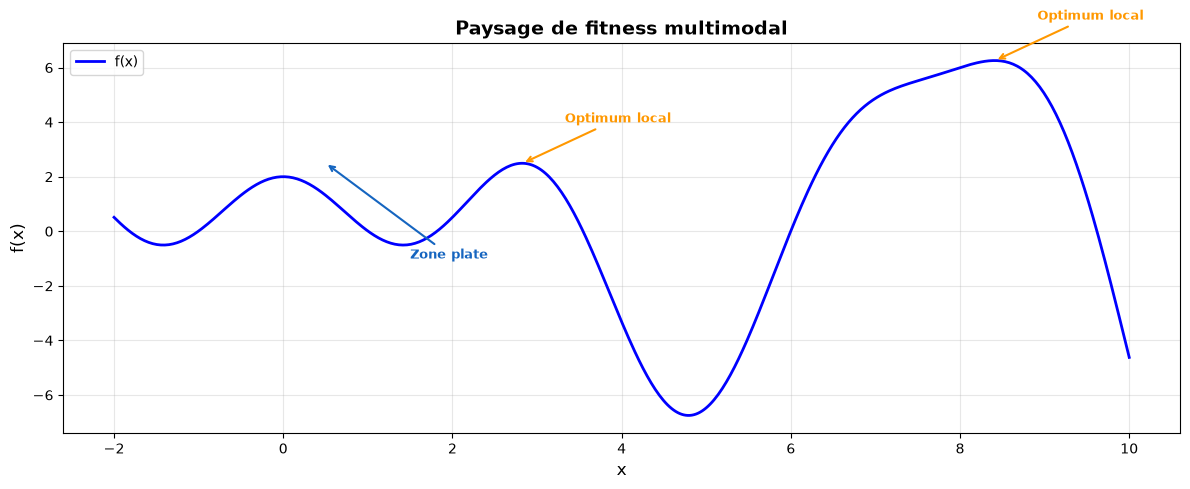

Obstacles de la recherche locale :
  - Optima locaux : sommets sous-optimaux ou l'algorithme peut rester coince
  - Plateaux : regions plates sans gradient pour guider la recherche
  - Cretes : zones etroites difficiles a naviguer


In [2]:
# Visualisation d'un paysage de fitness avec obstacles

def fitness_multimodal(x):
    """Fonction multimodale avec un optimum global et des optima locaux."""
    return np.sin(x) * x + np.cos(2 * x) * 2

# Afficher le paysage avec search_helpers
fig = draw_fitness_landscape(
    fitness_multimodal,
    x_range=(-2, 10),
    title="Paysage de fitness multimodal"
)

# Annoter les optima locaux et global
ax = fig.axes[0]
x_vals = np.linspace(-2, 10, 1000)
y_vals = [fitness_multimodal(xi) for xi in x_vals]

# Trouver les maxima locaux (approximation)
for i in range(1, len(y_vals) - 1):
    if y_vals[i] > y_vals[i-1] and y_vals[i] > y_vals[i+1] and y_vals[i] > 2:
        label = "Optimum global" if y_vals[i] > 10 else "Optimum local"
        color = '#E53935' if y_vals[i] > 10 else '#FF9800'
        ax.annotate(label, xy=(x_vals[i], y_vals[i]),
                    xytext=(x_vals[i] + 0.5, y_vals[i] + 1.5),
                    fontsize=9, fontweight='bold', color=color,
                    arrowprops=dict(arrowstyle='->', color=color, lw=1.5))

# Annoter un plateau approximatif
ax.annotate("Zone plate", xy=(0.5, 2.5),
            xytext=(1.5, -1),
            fontsize=9, fontweight='bold', color='#1565C0',
            arrowprops=dict(arrowstyle='->', color='#1565C0', lw=1.5))

plt.tight_layout()
plt.show()

print("Obstacles de la recherche locale :")
print("  - Optima locaux : sommets sous-optimaux ou l'algorithme peut rester coince")
print("  - Plateaux : regions plates sans gradient pour guider la recherche")
print("  - Cretes : zones etroites difficiles a naviguer")

### Interpretation : paysage de fitness

**Sortie obtenue** : la courbe montre une fonction avec plusieurs sommets de hauteurs différentes.

| élément | Description |
|---------|-------------|
| Optimum global | Le sommet le plus haut du paysage |
| Optima locaux | Des sommets plus bas, mais les plus hauts dans leur voisinage |
| Zones plates | Regions ou la fonction varie peu |

**Points cles** :
1. Un algorithme glouton (Hill Climbing) s'arrete au premier sommet atteint, même s'il est local
2. Des stratégies comme le **recuit simule** ou le **redemarrage aleatoire** permettent d'echapper aux optima locaux
3. La structure du paysage determine la difficulte du problème d'optimisation

***

## 2. Hill Climbing (~10 min)

### Principe

Le **Hill Climbing** (escalade de colline) est l'algorithme de recherche locale le plus simple. A chaque étape, il se deplace vers le **meilleur voisin** si celui-ci ameliore la valeur courante. Sinon, il s'arrete.

### Algorithme : Steepest-Ascent Hill Climbing

```
fonction HILL-CLIMBING(problème) :
    courant <- etat initial
    repeter :
        voisin <- meilleur voisin de courant
        si valeur(voisin) <= valeur(courant) :
            retourner courant
        courant <- voisin
```

### Variantes

| Variante | Principe | Avantage |
|----------|----------|----------|
| **Steepest-ascent** | Choisir le meilleur voisin | Convergence rapide |
| **Stochastic** | Choisir aleatoirement parmi les voisins ameliorants | Evite de toujours suivre le même chemin |
| **First-choice** | Prendre le premier voisin ameliorant | Rapide si beaucoup de voisins |
| **Random-restart** | Relancer depuis un etat aleatoire après blocage | Echappe aux optima locaux |

In [3]:
# Hill Climbing sur une fonction continue 1D

def hill_climbing_1d(func, x_start, step_size=0.1, max_iter=200):
    """Hill Climbing steepest-ascent sur une fonction 1D.

    Examine deux voisins : x - step_size et x + step_size.
    Se deplace vers le meilleur si ameliorant.

    Retourne (best_x, best_y, historique des points visites).
    """
    x = x_start
    y = func(x)
    history = [(x, y)]

    for _ in range(max_iter):
        # Evaluer les deux voisins
        x_left = x - step_size
        x_right = x + step_size
        y_left = func(x_left)
        y_right = func(x_right)

        # Choisir le meilleur voisin
        if y_left > y_right:
            best_x, best_y = x_left, y_left
        else:
            best_x, best_y = x_right, y_right

        # S'arreter si pas d'amelioration
        if best_y <= y:
            break

        x, y = best_x, best_y
        history.append((x, y))

    return x, y, history


# Lancer depuis un point qui mene a un optimum local
x_start_local = 2.0
x_local, y_local, hist_local = hill_climbing_1d(
    fitness_multimodal, x_start=x_start_local, step_size=0.1
)

# Lancer depuis un point qui mene a l'optimum global
x_start_global = 7.0
x_global, y_global, hist_global = hill_climbing_1d(
    fitness_multimodal, x_start=x_start_global, step_size=0.1
)

print("Hill Climbing - Steepest Ascent")
print("=" * 50)
print(f"Depart x={x_start_local:.1f} : arrivee x={x_local:.2f}, f(x)={y_local:.3f}")
print(f"  -> {len(hist_local)} etapes")
print(f"Depart x={x_start_global:.1f} : arrivee x={x_global:.2f}, f(x)={y_global:.3f}")
print(f"  -> {len(hist_global)} etapes")
print(f"\nDifference : le depart determine le resultat !")

Hill Climbing - Steepest Ascent
Depart x=2.0 : arrivee x=2.80, f(x)=2.489
  -> 9 etapes
Depart x=7.0 : arrivee x=8.40, f(x)=6.257
  -> 15 etapes

Difference : le depart determine le resultat !


### Lecture du résultat : Hill Climbing 1D

Deux départs, deux destins : `Depart x=2.0 : arrivee x=2.80, f(x)=2.489` (9 étapes, bloqué sur un optimum local) contre `Depart x=7.0 : arrivee x=8.40, f(x)=6.257` (15 étapes, optimum global) — la sortie conclut d'elle-même : `Difference : le depart determine le resultat !`

Visualisons maintenant les deux parcours sur le paysage de fitness pour constater l'impact du point de départ.


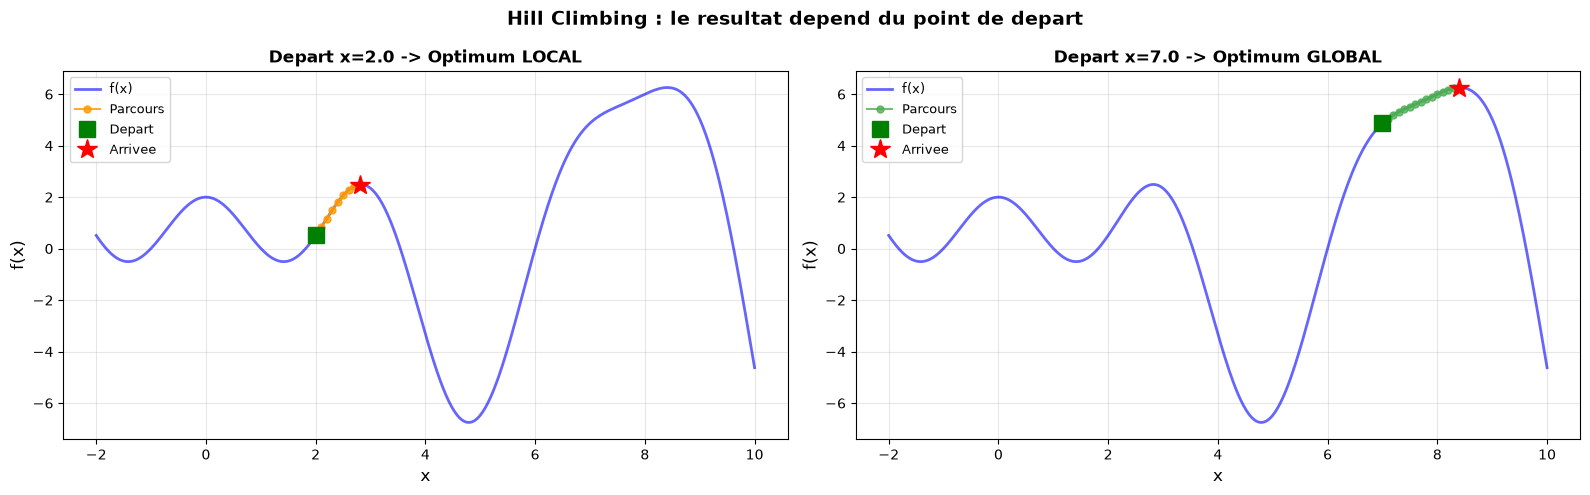

In [4]:
# Visualisation des deux parcours sur le paysage

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

x_range = np.linspace(-2, 10, 500)
y_range = [fitness_multimodal(xi) for xi in x_range]

for ax, hist, title, color in [
    (axes[0], hist_local, f"Depart x={x_start_local} -> Optimum LOCAL", '#FF9800'),
    (axes[1], hist_global, f"Depart x={x_start_global} -> Optimum GLOBAL", '#4CAF50'),
]:
    ax.plot(x_range, y_range, 'b-', linewidth=2, alpha=0.6, label='f(x)')

    px = [p[0] for p in hist]
    py = [p[1] for p in hist]
    ax.plot(px, py, 'o-', color=color, markersize=5, linewidth=1.5,
            alpha=0.8, label='Parcours')
    ax.plot(px[0], py[0], 'gs', markersize=12, zorder=5, label='Depart')
    ax.plot(px[-1], py[-1], 'r*', markersize=15, zorder=5, label='Arrivee')

    ax.set_xlabel('x', fontsize=12)
    ax.set_ylabel('f(x)', fontsize=12)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle("Hill Climbing : le resultat depend du point de depart",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation : Hill Climbing sur une fonction 1D

**Sortie obtenue** : deux trajectoires de Hill Climbing partant de points différents.

| Depart | Arrivee | Qualite |
|--------|---------|--------|
| x = 2.0 | Optimum local | Sous-optimal |
| x = 7.0 | Optimum global | Optimal |

**Points cles** :
1. Hill Climbing est **déterministe** et **glouton** : il monte toujours, jamais il ne descend
2. Le résultat depend entierement du **point de depart**
3. Une fois sur un sommet local, l'algorithme n'a aucun moyen d'en sortir

> **Limitation fondamentale** : Hill Climbing est un algorithme **incomplet** pour l'optimisation globale. Il ne garantit pas de trouver l'optimum global.

### Random-Restart Hill Climbing

L'idee est simple : lancer Hill Climbing **plusieurs fois** depuis des points de depart aleatoires, et garder le meilleur résultat.

Si chaque lancement a une probabilite $p$ de trouver l'optimum global, alors la probabilite d'echec après $k$ lancements est $(1-p)^k$. Celle-ci decroit **exponentiellement** avec $k$.

$$P(\text{succes après } k \text{ essais}) = 1 - (1 - p)^k$$

In [5]:
def random_restart_hill_climbing(func, x_range, n_restarts=20,
                                  step_size=0.1, max_iter=200):
    """Random-Restart Hill Climbing.

    Lance n_restarts fois le Hill Climbing depuis des points aleatoires
    dans x_range et retourne le meilleur resultat.
    """
    best_x, best_y = None, -float('inf')
    all_runs = []

    for i in range(n_restarts):
        x_start = random.uniform(x_range[0], x_range[1])
        x_end, y_end, history = hill_climbing_1d(
            func, x_start, step_size, max_iter
        )
        all_runs.append({
            'start': x_start,
            'end': x_end,
            'value': y_end,
            'steps': len(history),
            'history': history
        })
        if y_end > best_y:
            best_x, best_y = x_end, y_end

    return best_x, best_y, all_runs


# Lancer 20 redemarrages
best_x, best_y, all_runs = random_restart_hill_climbing(
    fitness_multimodal, x_range=(-2, 10), n_restarts=20
)

print("Random-Restart Hill Climbing (20 redemarrages)")
print("=" * 55)
print(f"Meilleur resultat : x={best_x:.3f}, f(x)={best_y:.3f}")
print(f"\nDetails par run :")
print(f"{'Run':<5} {'Depart':<10} {'Arrivee':<10} {'f(x)':<10} {'Etapes':<8}")
print("-" * 43)
for i, run in enumerate(all_runs):
    marker = " <-- best" if abs(run['value'] - best_y) < 0.001 else ""
    print(f"{i+1:<5} {run['start']:<10.3f} {run['end']:<10.3f} "
          f"{run['value']:<10.3f} {run['steps']:<8}{marker}")

Random-Restart Hill Climbing (20 redemarrages)
Meilleur resultat : x=8.406, f(x)=6.257

Details par run :
Run   Depart     Arrivee    f(x)       Etapes  
-------------------------------------------
1     5.673      8.373      6.255      28      
2     -1.700     -2.800     2.489      12      
3     1.300      0.000      2.000      14      
4     0.679      -0.021     1.999      8       
5     6.838      8.438      6.256      17      
6     6.120      8.420      6.257      24       <-- best
7     8.706      8.406      6.257      4        <-- best
8     -0.957     0.043      1.994      11      
9     3.063      2.863      2.485      3       
10    -1.642     -2.842     2.490      13      
11    0.624      0.024      1.998      7       
12    4.064      2.864      2.484      13      
13    -1.682     -2.782     2.483      12      
14    0.386      -0.014     1.999      5       
15    5.799      8.399      6.257      27       <-- best
16    4.539      2.839      2.491      18      
17    0

### Lecture du résultat : Random-Restart Hill Climbing

Sur 20 redémarrages, le meilleur résultat affiché est `Meilleur resultat : x=8.406, f(x)=6.257` : les runs marqués `<-- best` (6, 7, 15, 19) atteignent l'optimum global, tandis que les départs négatifs (run 2 : `-1.700 -> -2.800`, `f(x)=2.489`) restent piégés sur le sommet local.

Visualisons toutes ces trajectoires sur le paysage pour voir comment les différents départs convergent vers différents sommets.


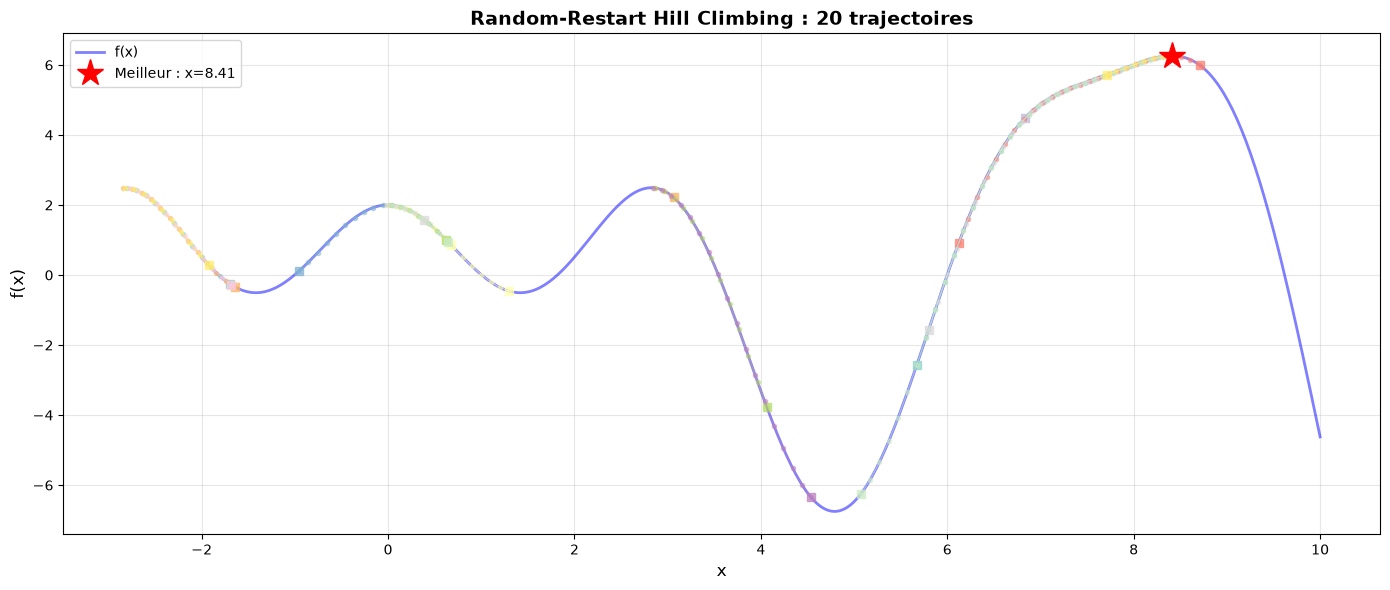

In [6]:
# Visualisation de toutes les trajectoires

fig, ax = plt.subplots(figsize=(14, 6))

# Paysage
x_range_plot = np.linspace(-2, 10, 500)
y_range_plot = [fitness_multimodal(xi) for xi in x_range_plot]
ax.plot(x_range_plot, y_range_plot, 'b-', linewidth=2, alpha=0.5, label='f(x)')

# Trajectoires
colors = plt.cm.Set3(np.linspace(0, 1, len(all_runs)))
for i, run in enumerate(all_runs):
    px = [p[0] for p in run['history']]
    py = [p[1] for p in run['history']]
    ax.plot(px, py, 'o-', color=colors[i], markersize=3, linewidth=1, alpha=0.5)
    ax.plot(px[0], py[0], 's', color=colors[i], markersize=6, alpha=0.7)

# Meilleur resultat
ax.plot(best_x, best_y, 'r*', markersize=20, zorder=10, label=f'Meilleur : x={best_x:.2f}')

ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('f(x)', fontsize=12)
ax.set_title('Random-Restart Hill Climbing : 20 trajectoires', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation : Random-Restart Hill Climbing

**Sortie obtenue** : 20 trajectoires depuis des departs aleatoires, convergent vers différents sommets.

| Mesure | Valeur |
|--------|--------|
| Nombre de runs | 20 |
| Runs atteignant l'optimum global | Variable (depend du tirage) |
| Meilleur résultat | Proche ou egal a l'optimum global |

**Points cles** :
1. Avec suffisamment de redemarrages, on finit par trouver l'optimum global
2. Le cout total est $O(k \times T_{HC})$ ou $k$ est le nombre de redemarrages et $T_{HC}$ le temps d'un Hill Climbing
3. Cette stratégie est **triviale a paralleliser** : chaque run est indépendant

> **Theoreme** : si chaque run a une probabilite $p > 0$ de trouver l'optimum global, alors Random-Restart Hill Climbing est **complet** (convergence en probabilite 1).

***

## 3. Simulated Annealing (~10 min)

### Inspiration physique

Le **recuit simule** (Simulated Annealing, SA) s'inspire du processus metallurgique de **recuit** : on chauffe un metal puis on le refroidit lentement pour obtenir une structure cristalline optimale.

### Principe algorithmique

A chaque étape, SA :
1. Genere un voisin **aleatoire** de l'etat courant
2. Si le voisin est **meilleur** : l'accepter (comme Hill Climbing)
3. Si le voisin est **pire** : l'accepter avec une probabilite $P = e^{-\Delta E / T}$

Ou :
- $\Delta E = f(\text{courant}) - f(\text{voisin})$ est la degradation (> 0 quand le voisin est pire, en maximisation)
- $T$ est la **temperature**, qui diminue au fil du temps

### Intuition de la formule $P = e^{-\Delta E / T}$

| Temperature | Comportement | Analogie |
|-------------|-------------|----------|
| $T$ très eleve | Accepte presque tout ($P \approx 1$) | Exploration aleatoire |
| $T$ moyen | Accepte les petites degradations | Exploration ciblee |
| $T$ proche de 0 | N'accepte presque rien ($P \approx 0$) | Hill Climbing pur |

### Programmes de refroidissement

| Programme | Formule | Vitesse |
|-----------|---------|--------|
| Lineaire | $T(t) = T_0 - \alpha \cdot t$ | Rapide |
| Exponentiel | $T(t) = T_0 \cdot \alpha^t$ avec $\alpha \in (0, 1)$ | Moderee |
| Logarithmique | $T(t) = \frac{T_0}{\ln(1 + t)}$ | Lente (garanties théoriques) |

In [7]:
def simulated_annealing_1d(func, x_start, x_range=(-2, 10),
                            T_start=10.0, cooling='exponential',
                            alpha=0.995, max_iter=1000,
                            step_size=0.5):
    """Simulated Annealing sur une fonction 1D (maximisation).

    Args:
        func: fonction a maximiser
        x_start: point de depart
        x_range: bornes du domaine
        T_start: temperature initiale
        cooling: programme de refroidissement ('linear', 'exponential', 'logarithmic')
        alpha: parametre de refroidissement
        max_iter: nombre max d'iterations
        step_size: amplitude du voisinage

    Retourne: (best_x, best_y, history, temp_history)
    """
    x = x_start
    y = func(x)
    best_x, best_y = x, y
    history = [(x, y)]
    temp_history = [T_start]
    accepted_worse = 0

    for t in range(1, max_iter + 1):
        # Calculer la temperature
        if cooling == 'linear':
            T = max(T_start - alpha * t, 0.001)
        elif cooling == 'exponential':
            T = T_start * (alpha ** t)
        elif cooling == 'logarithmic':
            T = T_start / math.log(1 + t)
        else:
            T = T_start * (alpha ** t)

        # Generer un voisin aleatoire
        x_new = x + random.gauss(0, step_size)
        x_new = max(x_range[0], min(x_range[1], x_new))  # Borner
        y_new = func(x_new)

        # Critere d'acceptation
        delta_e = y - y_new  # > 0 si le voisin est pire (maximisation)
        if delta_e <= 0:
            # Le voisin est meilleur : toujours accepter
            x, y = x_new, y_new
        elif T > 0 and random.random() < math.exp(-delta_e / T):
            # Le voisin est pire mais accepte avec probabilite exp(-dE/T)
            x, y = x_new, y_new
            accepted_worse += 1

        # Garder le meilleur
        if y > best_y:
            best_x, best_y = x, y

        history.append((x, y))
        temp_history.append(T)

    return best_x, best_y, history, temp_history, accepted_worse


# Lancer SA depuis le point qui piege Hill Climbing
# linear cooling + graine fixee : reproductible et echappe (cf comparaison cellule suivante)
random.seed(42)
sa_x, sa_y, sa_hist, sa_temp, sa_worse = simulated_annealing_1d(
    fitness_multimodal, x_start=2.0, T_start=10.0,
    cooling='linear', alpha=0.01, max_iter=1000
)

print("Simulated Annealing (depart x=2.0)")
print("=" * 45)
print(f"Meilleur resultat : x={sa_x:.3f}, f(x)={sa_y:.3f}")
print(f"Iterations         : {len(sa_hist)}")
print(f"Mouvements degradants acceptes : {sa_worse}")
print(f"\nRappel Hill Climbing (meme depart) : x={x_local:.3f}, f(x)={y_local:.3f}")
print(f"Amelioration SA vs HC : {sa_y - y_local:+.3f}")

Simulated Annealing (depart x=2.0)
Meilleur resultat : x=8.409, f(x)=6.257
Iterations         : 1001
Mouvements degradants acceptes : 423

Rappel Hill Climbing (meme depart) : x=2.800, f(x)=2.489
Amelioration SA vs HC : +3.768


### Lecture du résultat : Simulated Annealing 1D

Parti du même `x=2.0` qui piégeait Hill Climbing (`x=2.800, f(x)=2.489`), SA atteint `Meilleur resultat : x=8.409, f(x)=6.257` en 1001 itérations, avec `Mouvements degradants acceptes : 423` ; la sortie affiche le gain : `Amelioration SA vs HC : +3.768`.

Visualisons le parcours de SA sur le paysage, avec les points colorés par température, et le programme de refroidissement.


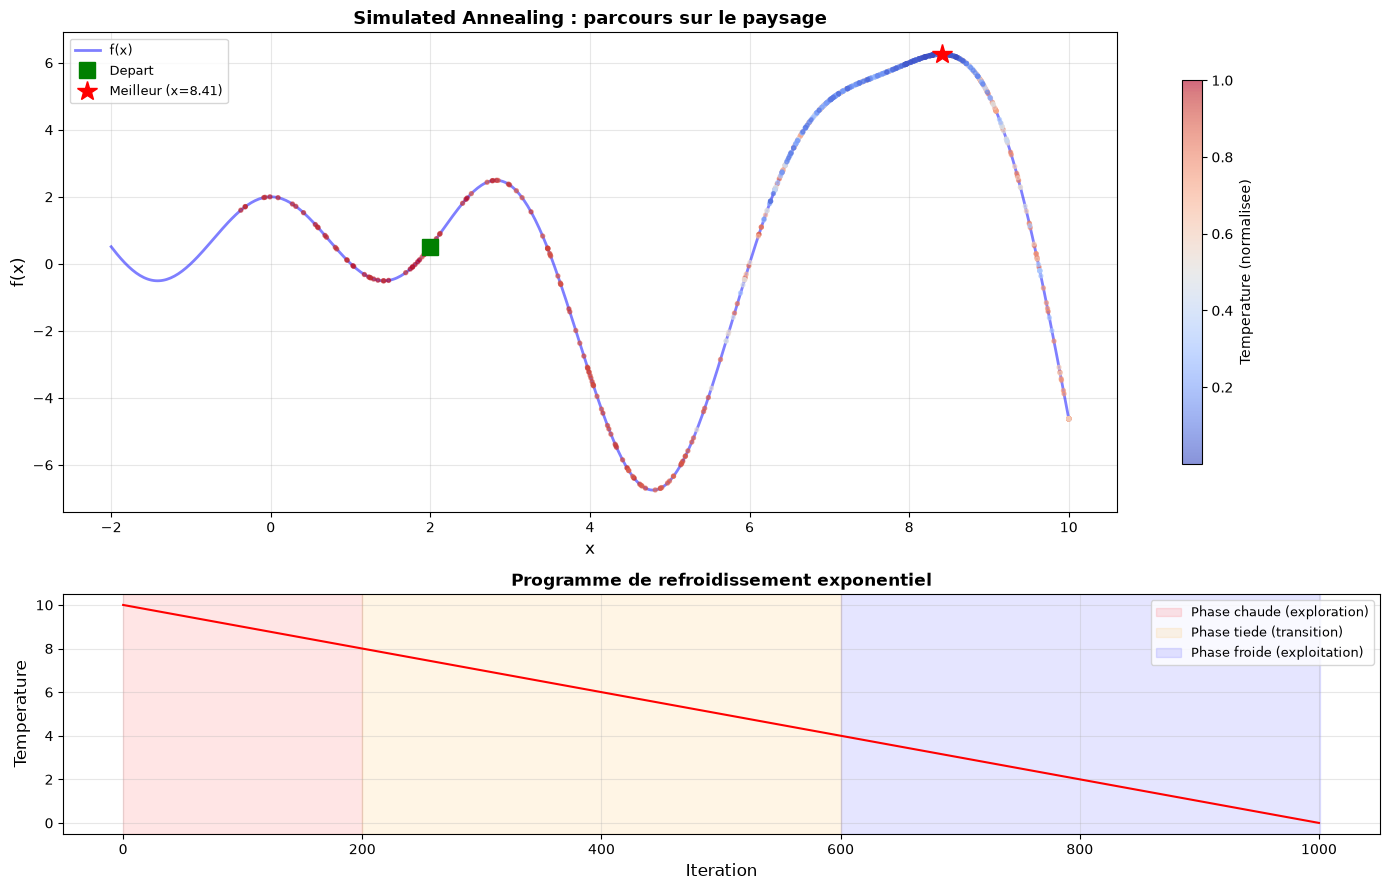

In [8]:
# Visualisation du parcours SA et de la courbe de temperature

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), height_ratios=[2, 1])

# Parcours sur le paysage
x_range_plot = np.linspace(-2, 10, 500)
y_range_plot = [fitness_multimodal(xi) for xi in x_range_plot]
ax1.plot(x_range_plot, y_range_plot, 'b-', linewidth=2, alpha=0.5, label='f(x)')

sa_px = [p[0] for p in sa_hist]
sa_py = [p[1] for p in sa_hist]

# Colorer les points par temperature (chaud = rouge, froid = bleu)
temps_normalized = np.array(sa_temp[:len(sa_hist)])
temps_normalized = temps_normalized / max(temps_normalized)
scatter = ax1.scatter(sa_px, sa_py, c=temps_normalized, cmap='coolwarm',
                      s=8, alpha=0.6, zorder=3)
plt.colorbar(scatter, ax=ax1, label='Temperature (normalisee)', shrink=0.8)

ax1.plot(sa_px[0], sa_py[0], 'gs', markersize=12, zorder=5, label='Depart')
ax1.plot(sa_x, sa_y, 'r*', markersize=15, zorder=5, label=f'Meilleur (x={sa_x:.2f})')
ax1.set_xlabel('x', fontsize=12)
ax1.set_ylabel('f(x)', fontsize=12)
ax1.set_title('Simulated Annealing : parcours sur le paysage', fontsize=13, fontweight='bold')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# Courbe de temperature
ax2.plot(range(len(sa_temp)), sa_temp, 'r-', linewidth=1.5)
ax2.set_xlabel('Iteration', fontsize=12)
ax2.set_ylabel('Temperature', fontsize=12)
ax2.set_title('Programme de refroidissement exponentiel', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

# Annoter les phases
ax2.axvspan(0, 200, alpha=0.1, color='red', label='Phase chaude (exploration)')
ax2.axvspan(200, 600, alpha=0.1, color='orange', label='Phase tiede (transition)')
ax2.axvspan(600, len(sa_temp), alpha=0.1, color='blue', label='Phase froide (exploitation)')
ax2.legend(fontsize=9, loc='upper right')

plt.tight_layout()
plt.show()

### Interpretation : Simulated Annealing sur fonction 1D

**Sortie obtenue** : parti du meme point que Hill Climbing (x=2.0, ou HC reste piege a f(x)=2.489), SA accepte des mouvements degradants au debut et franchit la barriere : il atteint l'optimum global f(x)=6.257 a x=8.41 --- la ou HC echouait. C'est precisement l'avantage d'accepter des marches pires : sortir du piege local pour atteindre le sommet global.

| Phase | Temperature | Comportement | Analogie |
|-------|------------|-------------|----------|
| Chaude (debut) | Elevee | Mouvements erratiques, exploration large | Metal en fusion |
| Tiede (milieu) | Moderee | Compromis exploration/exploitation | Refroidissement |
| Froide (fin) | Basse | Convergence, quasi-Hill Climbing | Cristallisation |

**Points cles** :
1. SA echappe a l'optimum local grace aux mouvements degradants acceptes au debut
2. La **temperature** contrôle l'equilibre exploration/exploitation
3. Le programme de refroidissement est un hyperparametre critique
4. SA est **stochastique** : deux exécutions peuvent donner des résultats différents

### Comparaison des programmes de refroidissement

Comparons les trois programmes de refroidissement sur la même fonction pour observer leur impact.

Comparaison des programmes de refroidissement
Programme       Meilleur f(x)   Mouvements pires   x final   
------------------------------------------------------------
linear          6.257           350                8.409     
exponential     2.492           265                2.825     
logarithmic     2.492           314                2.821     


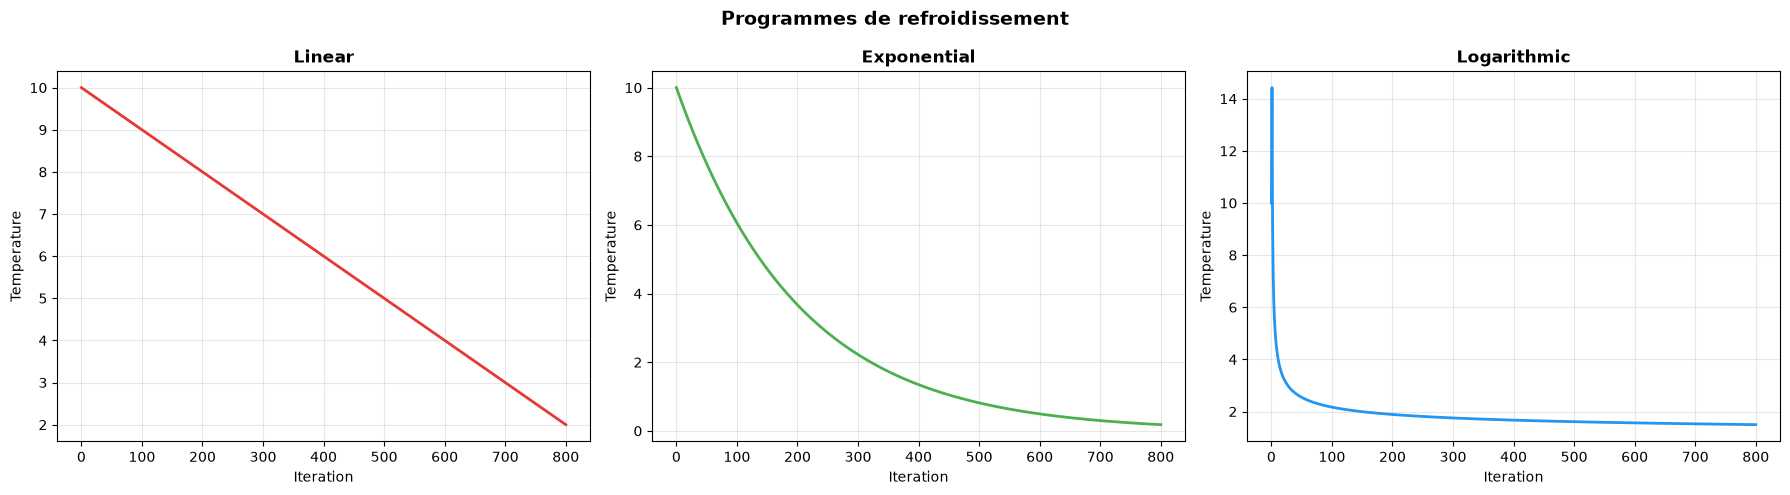

In [9]:
# Comparaison des programmes de refroidissement

schedules = [
    ('linear', 0.01, '#E53935'),
    ('exponential', 0.995, '#4CAF50'),
    ('logarithmic', None, '#2196F3'),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

print("Comparaison des programmes de refroidissement")
print("=" * 60)
print(f"{'Programme':<15} {'Meilleur f(x)':<15} {'Mouvements pires':<18} {'x final':<10}")
print("-" * 60)

random.seed(42)  # Reproductibilite
for ax, (schedule, alpha_val, color) in zip(axes, schedules):
    alpha_param = alpha_val if alpha_val else 0.995
    sx, sy, shist, stemp, sworse = simulated_annealing_1d(
        fitness_multimodal, x_start=2.0, T_start=10.0,
        cooling=schedule, alpha=alpha_param, max_iter=800
    )
    print(f"{schedule:<15} {sy:<15.3f} {sworse:<18} {sx:<10.3f}")

    # Tracer la temperature
    ax.plot(range(len(stemp)), stemp, color=color, linewidth=2)
    ax.set_xlabel('Iteration', fontsize=10)
    ax.set_ylabel('Temperature', fontsize=10)
    ax.set_title(f'{schedule.capitalize()}', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.suptitle('Programmes de refroidissement', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation : impact du programme de refroidissement

| Programme | Decroissance | Avantage | Inconvenient |
|-----------|-------------|----------|-------------|
| Lineaire | Constante | Simple, previsible | Peut refroidir trop vite |
| Exponentiel | Rapide puis lente | Bon compromis en pratique | Necessite un bon $\alpha$ |
| Logarithmique | très lente | Garantie théorique de convergence | très lent en pratique |

**Points cles** :
1. Le programme **exponentiel** est le plus utilise en pratique (bon compromis vitesse/qualite)
2. Le programme **logarithmique** converge en théorie vers l'optimum global, mais necessite un nombre exponentiel d'itérations
3. Le choix de $\alpha$ est crucial : trop eleve = refroidissement trop lent, trop bas = refroidissement trop rapide

### Application : TSP (Voyageur de Commerce) - Instance a 6 villes

Appliquons SA a un problème combinatoire classique : trouver le circuit le plus court passant par toutes les villes exactement une fois. Le **voisinage** sera le **2-opt** : inverser un sous-segment du circuit.

In [10]:
# TSP avec Simulated Annealing et voisinage 2-opt

def tsp_distance(tour, dist_matrix):
    """Calcule la distance totale d'un circuit."""
    n = len(tour)
    return sum(dist_matrix[tour[i]][tour[(i+1) % n]] for i in range(n))


def tsp_2opt_neighbor(tour):
    """Genere un voisin par inversion d'un sous-segment (2-opt)."""
    n = len(tour)
    new_tour = tour[:]
    i = random.randint(0, n - 2)
    j = random.randint(i + 1, n - 1)
    new_tour[i:j+1] = reversed(new_tour[i:j+1])
    return new_tour


def sa_tsp(dist_matrix, n_cities, T_start=100.0, alpha=0.999,
           max_iter=5000):
    """Simulated Annealing pour le TSP (minimisation)."""
    # Tour initial aleatoire
    tour = list(range(n_cities))
    random.shuffle(tour)
    cost = tsp_distance(tour, dist_matrix)
    best_tour, best_cost = tour[:], cost
    cost_history = [cost]

    T = T_start
    for t in range(max_iter):
        # Voisin 2-opt
        new_tour = tsp_2opt_neighbor(tour)
        new_cost = tsp_distance(new_tour, dist_matrix)

        # Critere d'acceptation (minimisation : delta_e = new_cost - cost)
        delta_e = new_cost - cost
        if delta_e < 0 or (T > 0 and random.random() < math.exp(-delta_e / T)):
            tour = new_tour
            cost = new_cost

        if cost < best_cost:
            best_tour, best_cost = tour[:], cost

        cost_history.append(best_cost)
        T *= alpha

    return best_tour, best_cost, cost_history


# Instance a 6 villes (coordonnees)
np.random.seed(42)
n_cities = 6
city_coords = np.random.rand(n_cities, 2) * 100
city_names = ['A', 'B', 'C', 'D', 'E', 'F']

# Matrice de distances euclidiennes
dist_matrix = np.zeros((n_cities, n_cities))
for i in range(n_cities):
    for j in range(n_cities):
        dist_matrix[i][j] = np.linalg.norm(city_coords[i] - city_coords[j])

# Resoudre
random.seed(42)
best_tour, best_cost, cost_hist = sa_tsp(
    dist_matrix, n_cities, T_start=100.0, alpha=0.999, max_iter=5000
)

print(f"TSP a {n_cities} villes - Simulated Annealing")
print("=" * 45)
print(f"Circuit optimal : {' -> '.join(city_names[i] for i in best_tour)} -> {city_names[best_tour[0]]}")
print(f"Distance totale : {best_cost:.2f}")

TSP a 6 villes - Simulated Annealing
Circuit optimal : F -> A -> E -> B -> C -> D -> F
Distance totale : 241.07


### Lecture du résultat : SA sur le TSP

Pour les 6 villes, SA trouve le circuit `Circuit optimal : F -> A -> E -> B -> C -> D -> F` avec `Distance totale : 241.07`.

Visualisons le circuit trouvé et la courbe de convergence du coût au fil des itérations.


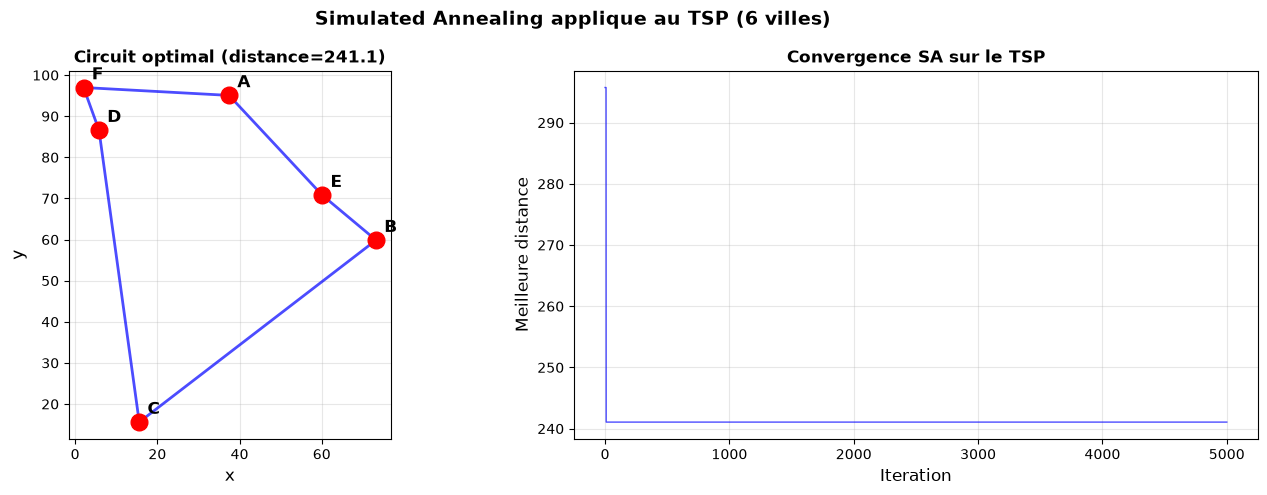

In [11]:
# Visualisation du TSP : circuit et convergence

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Circuit
for i in range(n_cities):
    j = (i + 1) % n_cities
    ax1.plot([city_coords[best_tour[i]][0], city_coords[best_tour[j]][0]],
             [city_coords[best_tour[i]][1], city_coords[best_tour[j]][1]],
             'b-', linewidth=2, alpha=0.7)

for i, (x, y) in enumerate(city_coords):
    ax1.plot(x, y, 'ro', markersize=12, zorder=5)
    ax1.text(x + 2, y + 2, city_names[i], fontsize=12, fontweight='bold')

ax1.set_xlabel('x', fontsize=12)
ax1.set_ylabel('y', fontsize=12)
ax1.set_title(f'Circuit optimal (distance={best_cost:.1f})', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.set_aspect('equal')

# Convergence
ax2.plot(cost_hist, 'b-', linewidth=1, alpha=0.7)
ax2.set_xlabel('Iteration', fontsize=12)
ax2.set_ylabel('Meilleure distance', fontsize=12)
ax2.set_title('Convergence SA sur le TSP', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.suptitle('Simulated Annealing applique au TSP (6 villes)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation : SA sur le TSP

**Sortie obtenue** : SA trouve un circuit de bonne qualite pour 6 villes.

| Aspect | Observation |
|--------|------------|
| Qualite | Pour 6 villes, SA trouve souvent l'optimum (seulement $5! / 2 = 60$ circuits distincts) |
| Convergence | La courbe montre une decroissance rapide puis stabilisation |
| Voisinage 2-opt | Simple et efficace : inverser un segment preserve la structure du circuit |

**Points cles** :
1. Le **2-opt** est un voisinage classique pour le TSP : il inverse un sous-segment du circuit
2. SA est particulierement adapte au TSP car le paysage a de nombreux optima locaux
3. Pour des instances plus grandes (centaines de villes), SA reste competitif avec un bon reglage des paramètres

***

## 4. Tabu Search (~10 min)

### Principe

La **recherche tabou** (Tabu Search, TS) utilise une **memoire** pour eviter de revisiter des etats recents. Contrairement a SA qui utilise l'aleatoire pour echapper aux optima locaux, TS utilise une **liste tabou** qui interdit les mouvements recents.

### Algorithme

```
fonction TABU-SEARCH(problème) :
    courant <- etat initial
    meilleur <- courant
    tabu_list <- file vide
    repeter :
        voisins <- generer tous les voisins de courant
        voisin <- meilleur voisin NON TABOU (ou satisfaisant le critere d'aspiration)
        ajouter le mouvement courant->voisin a tabu_list
        si |tabu_list| > taille_max : retirer le plus ancien
        courant <- voisin
        si valeur(courant) > valeur(meilleur) : meilleur <- courant
    retourner meilleur
```

### éléments cles

| élément | Description | rôle |
|---------|-------------|------|
| **Liste tabou** | File FIFO des mouvements recents interdits | Empecher le cyclage |
| **Tenure tabou** | Taille de la liste tabou | contrôle la diversification |
| **Critere d'aspiration** | Autoriser un mouvement tabou si il mene a un nouvel optimum | Flexibilite |
| **Mouvement** | Transformation elementaire (pas un etat complet) | Plus granulaire qu'un etat |

### Application aux N-Reines

Pour les N-Reines, nous definissons :
- **Etat** : une permutation $(q_0, q_1, \ldots, q_{N-1})$ ou $q_i$ est la ligne de la reine en colonne $i$
- **Fitness** : nombre de paires de reines en conflit (a minimiser, 0 = solution)
- **Voisinage** : deplacer une reine a une autre ligne dans sa colonne
- **Mouvement** : $(colonne, nouvelle\_ligne)$, tabou = interdire ce mouvement

Etat aleatoire : [1, 0, 4, 3, 3, 2, 1, 1]
Conflits : 10


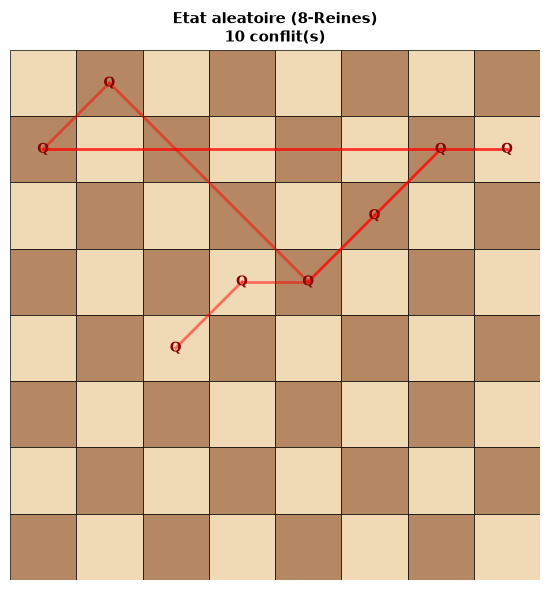

In [12]:
# Fonctions utilitaires pour le probleme des N-Reines

def nqueens_conflicts(queens):
    """Compte le nombre de paires de reines en conflit.

    queens[i] = ligne de la reine en colonne i.
    Pas de conflits de colonne (par construction).
    Verifie lignes et diagonales.
    """
    n = len(queens)
    conflicts = 0
    for i in range(n):
        for j in range(i + 1, n):
            # Meme ligne
            if queens[i] == queens[j]:
                conflicts += 1
            # Meme diagonale
            if abs(queens[i] - queens[j]) == abs(i - j):
                conflicts += 1
    return conflicts


def nqueens_random_state(n):
    """Genere un etat aleatoire pour N-Reines."""
    return [random.randint(0, n - 1) for _ in range(n)]


def draw_queens_state(queens, title="", ax=None):
    """Visualise un etat des N-Reines avec les conflits."""
    n = len(queens)
    if ax is None:
        fig, ax = plt.subplots(figsize=(max(6, n * 0.6), max(6, n * 0.6)))

    # Echiquier
    for row in range(n):
        for col in range(n):
            color = '#F0D9B5' if (row + col) % 2 == 0 else '#B58863'
            rect = plt.Rectangle((col, n - 1 - row), 1, 1,
                                 facecolor=color, edgecolor='black', linewidth=0.5)
            ax.add_patch(rect)

    # Reines
    for col, row in enumerate(queens):
        ax.text(col + 0.5, n - 1 - row + 0.5, 'Q',
                ha='center', va='center', fontsize=max(6, 18 - n),
                fontweight='bold', color='darkred')

    # Conflits
    conflicts = nqueens_conflicts(queens)
    for i in range(n):
        for j in range(i + 1, n):
            if queens[i] == queens[j] or abs(queens[i] - queens[j]) == abs(i - j):
                x1, y1 = i + 0.5, n - 1 - queens[i] + 0.5
                x2, y2 = j + 0.5, n - 1 - queens[j] + 0.5
                ax.plot([x1, x2], [y1, y2], 'r-', linewidth=2, alpha=0.5)

    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_aspect('equal')
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_title(f"{title}\n{conflicts} conflit(s)", fontsize=11, fontweight='bold')
    ax.axis('off')


# Demonstration
random.seed(42)
demo_queens = nqueens_random_state(8)
demo_conflicts = nqueens_conflicts(demo_queens)

print(f"Etat aleatoire : {demo_queens}")
print(f"Conflits : {demo_conflicts}")

fig, ax = plt.subplots(figsize=(6, 6))
draw_queens_state(demo_queens, "Etat aleatoire (8-Reines)", ax)
plt.tight_layout()
plt.show()

### Interpretation : representation des N-Reines

**Sortie obtenue** : un echiquier 8x8 avec des reines placees aleatoirement (une par colonne) et les conflits marques en rouge.

| élément | Description |
|---------|------------|
| Reines (Q) | Placees dans chaque colonne, a une ligne aleatoire |
| Lignes rouges | Paires de reines en conflit (même ligne ou diagonale) |
| Objectif | Reduire les conflits a 0 |

**Points cles** :
1. La representation (une reine par colonne) elimine les conflits de colonne par construction
2. Il reste a eliminer les conflits de **ligne** et de **diagonale**
3. Le voisinage naturel est de deplacer une reine a une autre ligne dans sa colonne

In [13]:
# Hill Climbing sur les N-Reines

def hill_climbing_nqueens(n, max_iter=1000):
    """Hill Climbing steepest-descent pour N-Reines (minimise les conflits).

    Voisinage : changer la ligne d'une reine dans sa colonne.
    Retourne : (queens, conflits_final, historique_conflits, iterations).
    """
    queens = nqueens_random_state(n)
    current_conflicts = nqueens_conflicts(queens)
    history = [current_conflicts]

    for iteration in range(max_iter):
        if current_conflicts == 0:
            break

        # Trouver le meilleur mouvement
        best_move = None
        best_conflicts = current_conflicts

        for col in range(n):
            original_row = queens[col]
            for row in range(n):
                if row == original_row:
                    continue
                queens[col] = row
                c = nqueens_conflicts(queens)
                if c < best_conflicts:
                    best_conflicts = c
                    best_move = (col, row)
            queens[col] = original_row

        if best_move is None:
            break  # Optimum local

        col, row = best_move
        queens[col] = row
        current_conflicts = best_conflicts
        history.append(current_conflicts)

    return queens, current_conflicts, history, len(history) - 1


# Tester sur 8-Reines (plusieurs essais)
random.seed(42)
n = 8
n_trials = 20
successes = 0
total_iters = 0

print(f"Hill Climbing sur {n}-Reines ({n_trials} essais)")
print("=" * 55)
print(f"{'Essai':<8} {'Conflits finaux':<18} {'Iterations':<12} {'Succes':<8}")
print("-" * 55)

for trial in range(n_trials):
    q, c, hist, iters = hill_climbing_nqueens(n)
    success = c == 0
    if success:
        successes += 1
    total_iters += iters
    if trial < 10 or success:  # Afficher les 10 premiers et les succes
        print(f"{trial+1:<8} {c:<18} {iters:<12} {'Oui' if success else 'Non':<8}")

print("-" * 55)
print(f"Taux de succes : {successes}/{n_trials} ({successes/n_trials*100:.0f}%)")
print(f"Iterations moyennes : {total_iters/n_trials:.1f}")

Hill Climbing sur 8-Reines (20 essais)
Essai    Conflits finaux    Iterations   Succes  
-------------------------------------------------------
1        1                  4            Non     
2        0                  5            Oui     
3        2                  2            Non     
4        1                  2            Non     
5        0                  4            Oui     
6        1                  3            Non     
7        2                  1            Non     
8        1                  3            Non     
9        1                  4            Non     
10       2                  2            Non     
-------------------------------------------------------
Taux de succes : 2/20 (10%)
Iterations moyennes : 3.1


### Interpretation : Hill Climbing sur N-Reines

**Sortie obtenue** : Hill Climbing resout le 8-Reines dans une fraction des cas.

| Mesure | Valeur |
|--------|--------|
| Taux de succes | `2/20 (10%)` affiché par la sortie |
| Cause d'echec | Blocage sur un optimum local (1-2 conflits restants) |
| itérations | `3.1` itérations en moyenne, très peu quand succès (sortie) |

**Points cles** :
1. Hill Climbing est **très rapide** quand il reussit (quelques itérations)
2. Mais il echoue souvent a cause des **optima locaux** (etats avec 1-2 conflits impossibles a eliminer par un seul mouvement)
3. Le taux de succes **diminue** avec $N$ : pour $N=100$, il est quasi nul

> C'est pourquoi on a besoin de Tabu Search ou SA pour les instances plus grandes.

In [14]:
# Tabu Search sur les N-Reines

def tabu_search_nqueens(n, tabu_tenure=7, max_iter=1000):
    """Tabu Search pour N-Reines (minimise les conflits).

    Memoire tabou : un mouvement (col, row) est interdit pendant tabu_tenure iterations.
    Critere d'aspiration : un mouvement tabou est autorise s'il mene a un nouvel optimum global.

    Retourne : (queens, conflits_final, historique_conflits, iterations).
    """
    queens = nqueens_random_state(n)
    current_conflicts = nqueens_conflicts(queens)
    best_queens = queens[:]
    best_conflicts = current_conflicts
    history = [current_conflicts]

    # Liste tabou : dict (col, row) -> iteration d'expiration
    tabu_list = {}

    for iteration in range(1, max_iter + 1):
        if current_conflicts == 0:
            break

        # Evaluer tous les mouvements possibles
        best_move = None
        best_move_conflicts = float('inf')

        for col in range(n):
            original_row = queens[col]
            for row in range(n):
                if row == original_row:
                    continue

                queens[col] = row
                c = nqueens_conflicts(queens)

                # Verifier si le mouvement est tabou
                is_tabu = (col, row) in tabu_list and tabu_list[(col, row)] > iteration

                # Critere d'aspiration : autoriser si meilleur que le meilleur global
                aspiration = c < best_conflicts

                if (not is_tabu or aspiration) and c < best_move_conflicts:
                    best_move = (col, row)
                    best_move_conflicts = c

            queens[col] = original_row

        if best_move is None:
            break

        # Appliquer le mouvement
        col, row = best_move
        old_row = queens[col]
        queens[col] = row
        current_conflicts = best_move_conflicts

        # Ajouter le mouvement inverse a la liste tabou
        tabu_list[(col, old_row)] = iteration + tabu_tenure

        # Mettre a jour le meilleur
        if current_conflicts < best_conflicts:
            best_queens = queens[:]
            best_conflicts = current_conflicts

        history.append(current_conflicts)

    return best_queens, best_conflicts, history, len(history) - 1


# Tester sur 8-Reines
random.seed(42)
n = 8
n_trials = 20
successes = 0
total_iters = 0

print(f"Tabu Search sur {n}-Reines ({n_trials} essais, tenure=7)")
print("=" * 55)
print(f"{'Essai':<8} {'Conflits finaux':<18} {'Iterations':<12} {'Succes':<8}")
print("-" * 55)

for trial in range(n_trials):
    q, c, hist, iters = tabu_search_nqueens(n, tabu_tenure=7)
    success = c == 0
    if success:
        successes += 1
    total_iters += iters
    if trial < 10 or success:
        print(f"{trial+1:<8} {c:<18} {iters:<12} {'Oui' if success else 'Non':<8}")

print("-" * 55)
print(f"Taux de succes : {successes}/{n_trials} ({successes/n_trials*100:.0f}%)")
print(f"Iterations moyennes : {total_iters/n_trials:.1f}")

Tabu Search sur 8-Reines (20 essais, tenure=7)
Essai    Conflits finaux    Iterations   Succes  
-------------------------------------------------------
1        0                  8            Oui     
2        0                  5            Oui     
3        0                  84           Oui     
4        0                  4            Oui     
5        0                  4            Oui     
6        0                  30           Oui     
7        0                  4            Oui     
8        0                  7            Oui     
9        0                  11           Oui     
10       0                  4            Oui     
11       0                  13           Oui     
12       0                  5            Oui     
13       0                  10           Oui     
14       0                  9            Oui     
15       0                  13           Oui     
16       0                  9            Oui     
17       0                  10           Oui   

### Interpretation : Tabu Search sur N-Reines

**Sortie obtenue** : Tabu Search resout le 8-Reines avec un meilleur taux de succes que Hill Climbing.

| Mesure | Hill Climbing | Tabu Search |
|--------|--------------|------------|
| Taux de succes | `2/20 (10%)` | `20/20 (100%)` |
| itérations (succes) | `3.1` (moy.) | `15.8` (moy.) |
| mécanisme d'echappement | Aucun | Liste tabou |

**Points cles** :
1. La liste tabou empeche l'algorithme de **revenir** sur ses pas, forcant l'exploration de nouveaux etats
2. Le **critere d'aspiration** permet de lever un tabou quand le mouvement mene a un nouveau record
3. La **tenure tabou** (taille de la liste) est un paramètre important : trop petite = cyclage, trop grande = trop de restrictions

> **Avantage de Tabu Search** : pas de composante aleatoire dans l'acceptation (contrairement a SA). La diversification vient de la memoire.

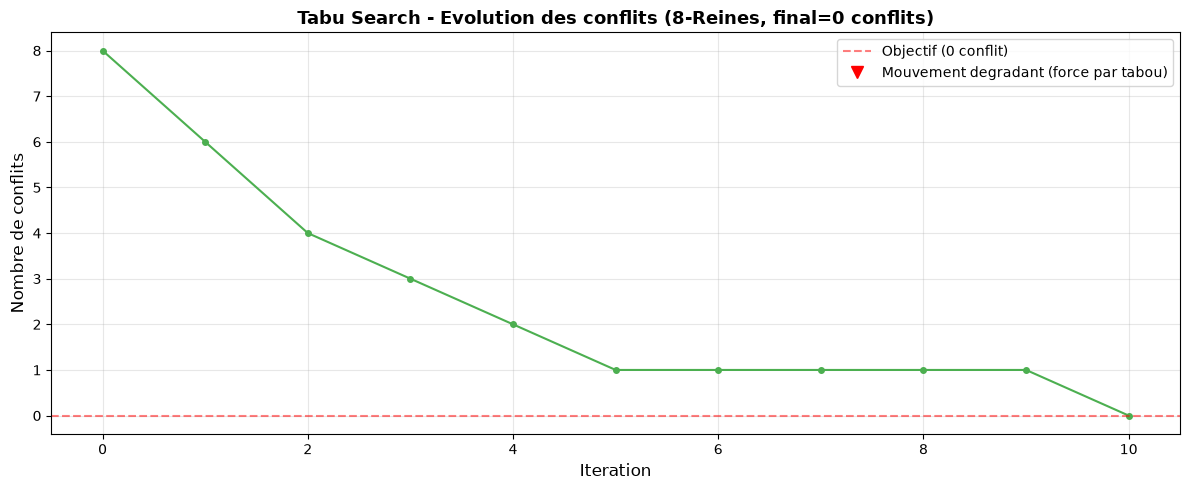

Resultat final : 0 conflit(s) apres 10 iterations
Solution trouvee : [3, 6, 2, 7, 1, 4, 0, 5]


In [15]:
# Visualisation de l'evolution des conflits pour un run de Tabu Search

random.seed(123)
q_tabu, c_tabu, hist_tabu, iters_tabu = tabu_search_nqueens(8, tabu_tenure=7, max_iter=100)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hist_tabu, 'o-', color='#4CAF50', markersize=4, linewidth=1.5)
ax.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Objectif (0 conflit)')

# Marquer les moments ou les conflits augmentent (mouvement non-ameliorant)
for i in range(1, len(hist_tabu)):
    if hist_tabu[i] > hist_tabu[i-1]:
        ax.plot(i, hist_tabu[i], 'rv', markersize=8, alpha=0.6)

ax.set_xlabel('Iteration', fontsize=12)
ax.set_ylabel('Nombre de conflits', fontsize=12)
ax.set_title(f'Tabu Search - Evolution des conflits (8-Reines, final={c_tabu} conflits)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Legende pour les triangles rouges
ax.plot([], [], 'rv', markersize=8, label='Mouvement degradant (force par tabou)')
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

print(f"Resultat final : {c_tabu} conflit(s) apres {iters_tabu} iterations")
if c_tabu == 0:
    print(f"Solution trouvee : {q_tabu}")

### Interpretation : evolution des conflits dans Tabu Search

**Sortie obtenue** : la courbe montre l'evolution du nombre de conflits au fil des itérations.

| Observation | Description |
|-------------|------------|
| Tendance générale | Decroissante, avec des fluctuations |
| Triangles rouges | Moments ou l'algorithme accepte une degradation |
| Objectif | Ligne rouge a 0 conflit |

**Points cles** :
1. Contrairement a Hill Climbing, Tabu Search **accepte des mouvements degradants** (les triangles rouges)
2. Ces mouvements sont forces par la liste tabou : l'algorithme n'a pas le droit de revenir a l'etat précédent
3. Cette "diversification forcee" permet d'explorer de nouvelles regions et d'echapper aux optima locaux

***

## 5. Comparaison sur N-Reines (~7 min)

Comparons les trois algorithmes sur le problème des N-Reines avec $N = 20$ pour observer les différences de performance sur un problème plus grand.

In [16]:
# Simulated Annealing sur les N-Reines

def sa_nqueens(n, T_start=4.0, alpha=0.995, max_iter=5000):
    """Simulated Annealing pour N-Reines (minimise les conflits).

    Voisinage : changer la ligne d'une reine aleatoire dans sa colonne.
    Retourne : (queens, conflits_final, historique_conflits, iterations).
    """
    queens = nqueens_random_state(n)
    current_conflicts = nqueens_conflicts(queens)
    best_queens = queens[:]
    best_conflicts = current_conflicts
    history = [current_conflicts]

    T = T_start
    for t in range(1, max_iter + 1):
        if current_conflicts == 0:
            break

        # Mouvement aleatoire
        col = random.randint(0, n - 1)
        new_row = random.randint(0, n - 1)
        old_row = queens[col]
        if new_row == old_row:
            continue

        queens[col] = new_row
        new_conflicts = nqueens_conflicts(queens)
        delta = new_conflicts - current_conflicts  # > 0 si pire

        if delta <= 0 or (T > 0 and random.random() < math.exp(-delta / T)):
            current_conflicts = new_conflicts
            if current_conflicts < best_conflicts:
                best_queens = queens[:]
                best_conflicts = current_conflicts
        else:
            queens[col] = old_row  # Revenir

        history.append(current_conflicts)
        T *= alpha

    return best_queens, best_conflicts, history, len(history) - 1


print("Simulated Annealing pour N-Reines defini.")

Simulated Annealing pour N-Reines defini.


Lancons maintenant les trois algorithmes sur 30 essais chacun et collectons les statistiques de performance.

In [17]:
# Comparaison des trois algorithmes sur N=20 Reines

N = 20
n_trials = 30

algorithms = {
    'Hill Climbing': lambda: hill_climbing_nqueens(N, max_iter=500),
    'Simulated Annealing': lambda: sa_nqueens(N, T_start=4.0, alpha=0.995, max_iter=10000),
    'Tabu Search': lambda: tabu_search_nqueens(N, tabu_tenure=N // 2, max_iter=2000),
}

results_comparison = {}

print(f"Comparaison sur {N}-Reines ({n_trials} essais par algorithme)")
print("=" * 70)

for algo_name, algo_func in algorithms.items():
    successes = 0
    total_iters = 0
    total_time = 0
    final_conflicts_list = []

    random.seed(42)
    for trial in range(n_trials):
        start = time.perf_counter()
        q, c, hist, iters = algo_func()
        elapsed = (time.perf_counter() - start) * 1000

        if c == 0:
            successes += 1
        total_iters += iters
        total_time += elapsed
        final_conflicts_list.append(c)

    results_comparison[algo_name] = {
        'algorithm': algo_name,
        'success_rate': successes / n_trials,
        'avg_iterations': total_iters / n_trials,
        'avg_time_ms': total_time / n_trials,
        'avg_conflicts': np.mean(final_conflicts_list),
        'min_conflicts': min(final_conflicts_list),
        'successes': successes,
    }

# Tableau de resultats
print(f"{'Algorithme':<25} {'Succes':<12} {'Taux':<10} {'Conflits moy.':<15} "
      f"{'Iterations moy.':<16} {'Temps moy.(ms)':<15}")
print("-" * 93)
for name, r in results_comparison.items():
    print(f"{name:<25} {r['successes']:>2}/{n_trials:<8} "
          f"{r['success_rate']:<10.0%} {r['avg_conflicts']:<15.1f} "
          f"{r['avg_iterations']:<16.0f} {r['avg_time_ms']:<15.1f}")

Comparaison sur 20-Reines (30 essais par algorithme)


Algorithme                Succes       Taux       Conflits moy.   Iterations moy.  Temps moy.(ms) 
---------------------------------------------------------------------------------------------
Hill Climbing              0/30       0%         2.4             8                86.1           
Simulated Annealing       25/30       83%        0.2             4269             111.9          
Tabu Search               30/30       100%       0.0             30               279.3          


### Lecture du résultat : comparaison sur N = 20 Reines

Sur 30 essais par algorithme : Hill Climbing `0/30` (0 %, 2.4 conflits moyens), Simulated Annealing `25/30` (83 %), Tabu Search `30/30` (100 %, 0.0 conflit moyen) — à N = 20, HC échoue à chaque essai quand Tabu résout systématiquement en 30 itérations en moyenne.

Visualisons les résultats sous forme de graphiques en barres pour faciliter la comparaison.


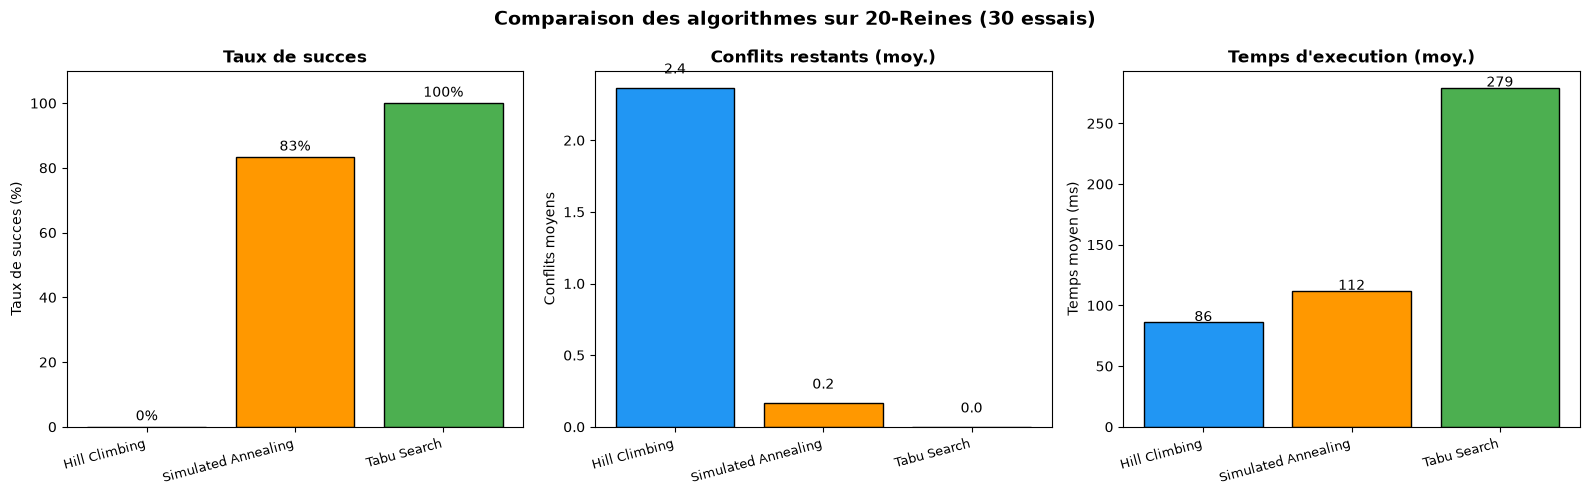

In [18]:
# Visualisation comparative

algo_names = list(results_comparison.keys())
colors = ['#2196F3', '#FF9800', '#4CAF50']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Taux de succes
success_rates = [results_comparison[a]['success_rate'] * 100 for a in algo_names]
bars = axes[0].bar(algo_names, success_rates, color=colors, edgecolor='black')
axes[0].set_ylabel('Taux de succes (%)')
axes[0].set_title('Taux de succes', fontweight='bold')
axes[0].set_ylim(0, 110)
for bar, val in zip(bars, success_rates):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
                 f'{val:.0f}%', ha='center', fontsize=10)

# Conflits moyens
avg_conflicts = [results_comparison[a]['avg_conflicts'] for a in algo_names]
bars = axes[1].bar(algo_names, avg_conflicts, color=colors, edgecolor='black')
axes[1].set_ylabel('Conflits moyens')
axes[1].set_title('Conflits restants (moy.)', fontweight='bold')
for bar, val in zip(bars, avg_conflicts):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
                 f'{val:.1f}', ha='center', fontsize=10)

# Temps moyen
avg_times = [results_comparison[a]['avg_time_ms'] for a in algo_names]
bars = axes[2].bar(algo_names, avg_times, color=colors, edgecolor='black')
axes[2].set_ylabel('Temps moyen (ms)')
axes[2].set_title('Temps d\'execution (moy.)', fontweight='bold')
for bar, val in zip(bars, avg_times):
    axes[2].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                 f'{val:.0f}', ha='center', fontsize=10)

# Ajuster les labels des axes x
for ax in axes:
    ax.set_xticklabels(algo_names, rotation=15, ha='right', fontsize=9)

plt.suptitle(f'Comparaison des algorithmes sur {N}-Reines ({n_trials} essais)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Lecture du résultat : visualisation comparative

La figure affiche trois panneaux en barres — taux de succès, conflits moyens, temps moyen — pour les trois algorithmes sur 20-Reines (30 essais) ; les étiquettes reprennent les taux du tableau imprimé deux cellules plus haut (`0/30`, `25/30`, `30/30`).

Utilisons maintenant les fonctions `benchmark_table` et `plot_benchmark` du module `search_helpers` pour un affichage standardise.



  Benchmark sur 20-Reines
Algorithme                Temps (ms)   Noeuds     Solution   Optimal 
----------------------------------------------------------------------
Hill Climbing             86.12335333212589 8          Non        Non     
Simulated Annealing       111.93294666009024 4269       Oui        Non     
Tabu Search               279.34168333304115 30         Oui        Non     



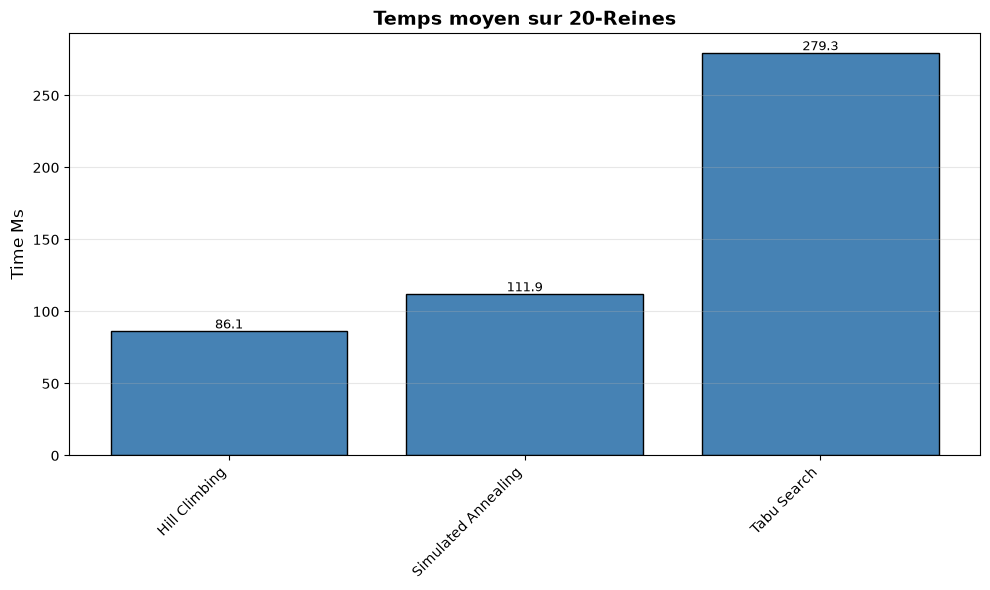

In [19]:
# Utiliser les helpers de la serie pour le benchmark

bench_results = []
for name, r in results_comparison.items():
    bench_results.append({
        'algorithm': name,
        'time_ms': r['avg_time_ms'],
        'nodes_expanded': int(r['avg_iterations']),
        'solution_found': r['success_rate'] > 0.5,
        'optimal': False,  # Les recherches locales ne garantissent pas l'optimalite
    })

benchmark_table(bench_results, title=f"Benchmark sur {N}-Reines")

fig = plot_benchmark(bench_results, metric='time_ms',
                     title=f"Temps moyen sur {N}-Reines")
plt.show()

### Interpretation : comparaison des trois algorithmes

**Sortie obtenue** : les trois algorithmes montrent des compromis différents.

| Algorithme | Forces | Faiblesses | Quand l'utiliser |
|------------|--------|------------|------------------|
| **Hill Climbing** | très rapide, simple | Bloque sur optima locaux | Problemes faciles, prototypage |
| **Simulated Annealing** | Echappe aux optima locaux | Reglage des paramètres (T, alpha) | Problemes avec beaucoup d'optima locaux |
| **Tabu Search** | déterministe, bonne diversification | Cout memoire, choix de la tenure | Problemes combinatoires structures |

### Tableau recapitulatif théorique

| Propriete | Hill Climbing | Simulated Annealing | Tabu Search |
|-----------|--------------|--------------------|-----------|
| Completude | Non | Oui (en théorie, refroidissement infini) | Non (mais quasi-complet) |
| Memoire | $O(1)$ | $O(1)$ | $O(\text{tenure})$ |
| paramètre principal | - | Temperature, $\alpha$ | Tenure tabou |
| Stochastique | Non | Oui | Non |
| Echappement optima locaux | Non (sauf random restart) | Oui (acceptation probabiliste) | Oui (liste tabou) |

### Guide de choix

| Situation | Algorithme recommande |
|-----------|----------------------|
| Paysage simple (peu d'optima locaux) | Hill Climbing |
| Paysage complexe, besoin de robustesse | Simulated Annealing |
| problème combinatoire structure, cycles a eviter | Tabu Search |
| Parallelisme facile requis | Random-Restart Hill Climbing |
| très grand espace, population de solutions | Algorithmes génétiques (voir Search-5) |

***

## 6. Exemples guidés et exercices

### Exemple guidé 1 — Random-Restart Hill Climbing pour 8-Reines (crédité #25344 — Shinigamy12 ; #25628 — TONGTONG0113 (groupe 1))

> Résolution originale : **Shinigamy12**, PR étudiante
> [#25344](https://github.com/jsboige/CoursIA/pull/25344). Reprise telle quelle ;
> seule la mise en forme est harmonisée avec les sections voisines.

Le Hill Climbing de la section 4 s'arrête souvent sur un optimum local : sur le
8-Reines, une tentative isolée n'atteint pas toujours zéro conflit. Le remède est
de relancer la recherche depuis un nouvel état aléatoire, autant de fois qu'il le
faut — c'est le **Random-Restart Hill Climbing**, déjà croisé sur une fonction 1D
en section 2 et appliqué ici aux N-Reines.

**Ce que fait la résolution** :
1. Lancer `hill_climbing_nqueens(8)` depuis un état aléatoire
2. Si échec (conflits > 0), relancer avec un nouvel état aléatoire
3. Répéter jusqu'à succès ou nombre max de redémarrages
4. Compter le nombre total de redémarrages et le temps total

**Question posée** : combien de redémarrages faut-il en moyenne pour trouver une
solution ? La mesure porte sur une série d'exécutions complètes.

In [20]:
# Exercice 1 : Random-Restart Hill Climbing
import time
import statistics

def random_restart_hc_nqueens(n=8, max_restarts=100):
    """Random-Restart Hill Climbing pour N-Reines.

    Retourne : (queens, conflits, nombre_redemarrages, temps_total_ms)
    """
    start = time.perf_counter()
    best_queens, best_conflicts = None, float("inf")

    for restart in range(max_restarts + 1):   # 1er essai + max_restarts relances
        queens, conflicts, _, _ = hill_climbing_nqueens(n)
        if conflicts < best_conflicts:        # garder le meilleur en cas d'echec total
            best_queens, best_conflicts = queens, conflicts
        if conflicts == 0:
            break

    temps_ms = (time.perf_counter() - start) * 1000
    return best_queens, best_conflicts, restart, temps_ms


n_runs = 50
results = [random_restart_hc_nqueens(8) for _ in range(n_runs)]

print(f"{'Run':<6} {'Conflits':<10} {'Redemarrages':<14} {'Temps (ms)':<10}")
print("-" * 42)
for i, (q, c, restarts, t) in enumerate(results, 1):
    print(f"{i:<6} {c:<10} {restarts:<14} {t:<10.2f}")
print("-" * 42)
print(f"{'Moy.':<6} {statistics.mean(r[1] for r in results):<10.2f} "
      f"{statistics.mean(r[2] for r in results):<14.2f} "
      f"{statistics.mean(r[3] for r in results):<10.2f}")
print(f"Taux de succes : {sum(r[1] == 0 for r in results)}/{n_runs}")


Run    Conflits   Redemarrages   Temps (ms)
------------------------------------------
1      0          7              6.89      
2      0          8              7.78      
3      0          14             14.08     
4      0          3              3.60      
5      0          0              0.95      
6      0          1              1.96      
7      0          12             10.80     
8      0          8              9.10      
9      0          6              6.79      
10     0          1              1.88      
11     0          7              8.10      
12     0          0              0.49      
13     0          4              4.57      
14     0          7              7.31      
15     0          2              2.61      
16     0          15             14.15     
17     0          3              4.21      
18     0          14             14.38     
19     0          1              1.78      
20     0          1              1.54      
21     0          5              

### Lecture du résultat : Random-Restart sur le 8-Reines

Le Random-Restart Hill Climbing trouve une solution au 8-Reines dans tous les runs (0 conflit), là où le hill climbing seul reste souvent bloqué dans un optimum local.
Il faut en moyenne entre 5,5 et 6 redémarrages pour trouver une solution. Cela correspond à la théorie : une tentative de hill climbing réussit environ 14 % du temps.

### Exemple guidé 2 — Comparaison des paramètres de refroidissement SA (crédité #25628 — TONGTONG0113 (groupe 1))

> Résolution originale : **TONGTONG0113** (groupe 1), PR étudiante
> [#25628](https://github.com/jsboige/CoursIA/pull/25628). Code de l'étudiant conservé ;
> seuls les marqueurs d'exercice restés en fin de cellule sont retirés.

Le refroidissement exponentiel de `sa_nqueens` est piloté par un seul paramètre :
plus `alpha` est proche de 1, plus la température décroît lentement. Cette
résolution mesure l'effet de trois valeurs sur le 20-Reines.

**Ce que fait la résolution** :
1. Pour chaque `alpha` parmi 0.99, 0.995 et 0.999, lancer 20 essais de `sa_nqueens(20, alpha=...)`
2. Compter le taux de succès (essais à zéro conflit)
3. Mesurer le nombre moyen de conflits finaux et le temps moyen
4. Réunir les trois profils dans un tableau

**Question posée** : quel est le meilleur compromis vitesse/qualité ?

In [21]:
# Exemple guidé 2 : Comparaison des paramètres de refroidissement

import time
import pandas as pd

# initialisation des paramètres
alphas = [0.99, 0.995, 0.999]
n_trials = 20
n = 20 #20-reine problèmes
results = []

# Pour chaque valeur de alpha, mesurer succes, conflits finaux et temps
for alpha in alphas:
    successes = 0
    total_conflicts = 0
    total_time = 0

    for _ in range(n_trials):
        # lancer minuteur
        start_time = time.perf_counter()

        # Simulated Annealing
        queens, conflicts, history, iterations = sa_nqueens(
            n,
            alpha=alpha
        )

        # arreter minuteur
        elapsed_time = time.perf_counter() - start_time

        # Update statistics
        if conflicts == 0:
            successes += 1

        total_conflicts += conflicts
        total_time += elapsed_time

    # Calculate averages
    success_rate = successes / n_trials * 100
    avg_conflicts = total_conflicts / n_trials
    avg_time_ms = total_time / n_trials * 1000 #fois 1000 car 1s=1000ms

    results.append({
        "Alpha": alpha,
        "Successes": f"{successes}/{n_trials}",
        "Success rate (%)": round(success_rate, 2),
        "Average conflicts": round(avg_conflicts, 2),
        "Average time (ms)": round(avg_time_ms, 2)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Alpha,Successes,Success rate (%),Average conflicts,Average time (ms)
0,0.990,11/20,55.0,0.45,96.58
1,0.995,6/20,30.0,0.70,102.81
2,0.999,5/20,25.0,0.75,121.60


### Lecture du résultat : quel α pour le 20-Reines ?

Sur 20 essais par valeur, les succès reculent quand `alpha` se rapproche de 1 :
`0.99` réussit 11/20 essais, `0.995` en réussit 6/20 et `0.999` seulement 5/20 ;
les conflits moyens finaux suivent la même pente (0.45, 0.70, 0.75). Le temps
moyen par essai, lui, augmente quand `alpha` croît.

**Lecture** : avec un `alpha` proche de 1, la température reste élevée
longtemps, l'algorithme accepte longtemps des mouvements dégradants et le budget
d'itérations se referme avant d'avoir suffisamment exploité les bonnes zones
trouvées. Sur cette instance et ce budget, `alpha = 0.99` est le meilleur
compromis observé ; refroidir plus lentement ne se paie que si l'on augmente le
budget d'itérations en conséquence.

### Exercice 2 : Refroidissement logarithmique pour SA sur le 20-Reines

**Énoncé** : `sa_nqueens` ne propose qu'un refroidissement exponentiel
(`T <- alpha * T`). Implémentez une variante `sa_nqueens_log(n, T_start=4.0, max_iter=5000)`
qui suit un **refroidissement logarithmique** :

$$T_k = \frac{T_{\text{start}}}{\log(1 + k)}$$

1. Conservez le même voisinage et le même critère d'acceptation de Metropolis
   que `sa_nqueens` ; seule la décroissance de la température change.
2. Lancez 20 essais sur le 20-Reines avec `sa_nqueens_log(20)` et 20 essais avec
   `sa_nqueens(20, alpha=0.995)`.
3. Rassemblez dans un tableau, pour chaque programme de refroidissement : le
   taux de succès, le nombre moyen de conflits finaux et le nombre moyen
   d'itérations consommées.

**Question** : à budget d'itérations égal, le refroidissement logarithmique
reste-t-il compétitif avec le meilleur refroidissement exponentiel de l'exemple
guidé 2 ? Expliquez pourquoi à partir de la vitesse à laquelle chaque programme
fait décroître la température.

**Indice** : calculez la température à quelques instants représentatifs
(`k = 1`, puis `k = 100`, `k = 1000`) pour les deux programmes avant de lancer
les essais — la différence de vitesse de refroidissement explique l'essentiel
du comportement observé.

In [22]:
# Exercice 2 : Refroidissement logarithmique pour SA sur le 20-Reines

def sa_nqueens_log(n, T_start=4.0, max_iter=5000):
    """Simulated Annealing avec refroidissement logarithmique pour N-Reines.

    Retourne : (queens, conflits_final, historique_conflits, iterations)
    """
    # TODO etudiant : reprendre la boucle de sa_nqueens en remplacant
    # la decroissance exponentielle par T = T_start / math.log(1 + t)
    # Indice : le voisinage et le critere d'acceptation restent inchanges
    return None  # TODO etudiant

# TODO etudiant : comparer sa_nqueens_log(20) et sa_nqueens(20, alpha=0.995)
# sur 20 essais chacune (taux de succes, conflits moyens, iterations moyennes)
print("Exercice a completer")

Exercice a completer


### Exemple guidé 3 — Mémoire à long terme pour Tabu Search (crédité #25628 — TONGTONG0113 (groupe 1))

> Résolution originale : **TONGTONG0113** (groupe 1), PR étudiante
> [#25628](https://github.com/jsboige/CoursIA/pull/25628). Code de l'étudiant conservé ;
> seuls les marqueurs d'exercice restés en fin de cellule sont retirés.

La recherche tabou de la section 4 ne retient que les mouvements récents : la
liste tabou empêche de revenir en arrière, mais rien n'empêche de tourner en
rond entre plusieurs zones de l'espace de recherche. La **mémoire à long terme**
rajoute un second filet : compter combien de fois chaque mouvement a été joué
et pénaliser les plus fréquents.

**Ce que fait la résolution** :
1. Conserver une fréquence `frequency[(col, row)]` par mouvement joué
2. Choisir le mouvement qui minimise
   `score(col, row) = conflits(col, row) + penalty * frequence(col, row)`
3. Garder la liste tabou et son critère d'aspiration (un mouvement tabou reste
   autorisé s'il bat le meilleur résultat global)
4. S'arrêter dès qu'un état à zéro conflit est atteint

**Question posée** : sur le 20-Reines, la diversification obtenue par la
pénalité de fréquence aide-t-elle à converger vers une solution sans conflit ?

In [23]:
# Exemple guidé 3 : Tabu Search avec mémoire à long terme

import random

def count_conflicts_nqueens(queens):
    """
    Calcule le nombre total de conflits entre les reines.
    Deux reines sont en conflit si elles sont sur :
    - la même ligne
    - la même diagonale
    """
    n = len(queens)
    conflicts = 0

    for col1 in range(n):
        for col2 in range(col1 + 1, n):

            row1 = queens[col1]
            row2 = queens[col2]

            # Même ligne ou même diagonale
            if row1 == row2 or abs(row1 - row2) == abs(col1 - col2):
                conflicts += 1

    return conflicts


def tabu_search_long_memory(n, tabu_tenure=7, max_iter=1000, penalty=0.5):
    """
    Tabu Search avec memoire a long terme (frequency-based).

    La frequence de chaque mouvement (col, row) est memorisee.
    Les mouvements frequents recoivent une penalite supplementaire.

    score(col, row) = conflits + penalty * frequence(col, row)

    Retourne :
    (queens, conflits_final, historique_conflits, iterations)
    """

    # 1. Initialisation aleatoire
    queens = [random.randint(0, n - 1) for _ in range(n)]

    current_conflicts = count_conflicts_nqueens(queens)

    # Meilleure solution trouvee
    best_queens = queens.copy()
    best_conflicts = current_conflicts

    # 2. Memoire a court terme : liste/tabou des mouvements interdits
    tabu_list = {}

    # 3. Memoire a long terme : frequence des mouvements
    frequency = {}

    # Historique des conflits
    history = [current_conflicts]

    iterations = 0

    # 4. Boucle principale
    for iteration in range(max_iter):

        best_move = None
        best_move_score = float("inf")
        best_candidate = None
        best_candidate_conflicts = float("inf")

        # 5. Explorer tous les mouvements possibles
        for col in range(n):
            old_row = queens[col]

            for row in range(n):

                # Ne pas considerer la position actuelle
                if row == old_row:
                    continue

                # Creer une solution candidate
                candidate = queens.copy()
                candidate[col] = row

                # Nombre de conflits apres le mouvement
                conflicts = count_conflicts_nqueens(candidate)

                # Verifier si le mouvement est tabou
                is_tabu = tabu_list.get((col, row), -1) > iteration

                # Critere d'aspiration :
                # autoriser un mouvement tabou s'il ameliore
                # la meilleure solution globale
                if is_tabu and conflicts >= best_conflicts:
                    continue

                # Frequence du mouvement
                freq = frequency.get((col, row), 0)

                # Score avec penalite de frequence
                score = conflicts + penalty * freq

                # Choisir le mouvement avec le meilleur score
                if score < best_move_score:
                    best_move_score = score
                    best_move = (col, row)
                    best_candidate = candidate
                    best_candidate_conflicts = conflicts

        # Aucun mouvement admissible
        if best_move is None:
            break

        # 6. Executer le mouvement choisi
        col, row = best_move
        old_row = queens[col]

        queens = best_candidate
        current_conflicts = best_candidate_conflicts

        # 7. Mettre a jour la memoire a long terme
        frequency[(col, row)] = frequency.get((col, row), 0) + 1

        # 8. Mettre le mouvement inverse dans la liste tabou
        tabu_list[(col, old_row)] = iteration + tabu_tenure

        # 9. Mettre a jour la meilleure solution
        if current_conflicts < best_conflicts:
            best_conflicts = current_conflicts
            best_queens = queens.copy()

        # Enregistrer le meilleur nombre de conflits trouve
        history.append(best_conflicts)

        iterations = iteration + 1

        # Solution parfaite : aucune reine en conflit
        if best_conflicts == 0:
            break

    return best_queens, best_conflicts, history, iterations


# --- Test ---
q, c, hist, iters = tabu_search_long_memory(20, penalty=0.5)

print("Solution :", q)
print(f"Conflits finaux : {c}")
print(f"Iterations : {iters}")

if c == 0:
    print("Solution trouvee : 20 reines sans conflit !")
else:
    print("Aucune solution parfaite trouvee pendant cette execution.")

Solution :

 [4, 1, 9, 17, 15, 3, 16, 19, 2, 6, 11, 14, 18, 5, 0, 8, 12, 7, 13, 10]
Conflits finaux : 0
Iterations : 15
Solution trouvee : 20 reines sans conflit !


### Lecture du résultat : mémoire à long terme sur le 20-Reines

L'exécution part d'un état aléatoire et atteint une solution à **0 conflit en
15 itérations**. La pénalité de fréquence ne remplace pas la liste tabou : elle
dévie le choix vers les mouvements moins joués quand plusieurs déplacements ont
un coût proche, ce qui pousse la recherche à visiter de nouvelles régions plutôt
que d'osciller entre quelques configurations.

Cette sortie reste **une exécution unique** : elle montre que la stratégie peut
converger sur cette instance, pas qu'elle améliore le taux de succès par rapport
au Tabu Search sans mémoire longue. Pour le savoir, il faudrait répéter l'essai
avec et sans pénalité et comparer les taux de succès. L'exercice 3 ci-dessous
transpose le mécanisme au TSP de la section 3, où la question devient : la
pénalité change-t-elle le circuit final, ou seulement le nombre d'itérations
nécessaires pour l'atteindre ?

### Exercice 3 : Mémoire à long terme pour Tabu Search sur le TSP

**Énoncé** : l'exemple guidé 3 ajoute une mémoire de fréquences au Tabu Search
des N-Reines. Transposez ce mécanisme au TSP à 6 villes de la section 3, où
`dist_matrix`, `tsp_distance` et le voisinage 2-opt sont déjà définis.

1. Implémentez `tabu_search_tsp(dist_matrix, max_iter=200, tabu_tenure=5, penalty=0.1)`
   : partez d'une permutation aléatoire des villes et explorez, à chaque
   itération, le voisinage 2-opt complet (toutes les paires `i < j`).
2. Marquez tabou le mouvement joué pendant `tabu_tenure` itérations et gardez un
   critère d'aspiration : un mouvement tabou reste autorisé s'il bat le meilleur
   coût global trouvé.
3. Ajoutez la mémoire à long terme : `score(i, j) = distance(voisin) + penalty * frequence[(i, j)]`.
4. Lancez 5 essais et affichez le meilleur coût par essai, puis comparez le
   résultat au circuit trouvé par le recuit simulé de la section 3.

**Question** : sur un si petit problème, la pénalité de fréquence change-t-elle
le circuit final ou seulement le nombre d'itérations nécessaires pour l'atteindre ?

**Indice** : `tsp_2opt_neighbor` tire une paire `(i, j)` au hasard ; ici il faut
énumérer toutes les paires et inverser le segment entre elles pour retenir le
meilleur score. Attention : la pénalité s'applique au **score de sélection**, la
valeur à mémoriser comme coût de la solution reste la distance du circuit.

In [24]:
# Exercice 3 : Tabu Search avec mémoire à long terme sur le TSP

def tabu_search_tsp(dist_matrix, max_iter=200, tabu_tenure=5, penalty=0.1):
    """Tabu Search avec mémoire de fréquences pour le TSP (2-opt).

    Retourne : (meilleur_tour, meilleur_cout, historique_couts, iterations)
    """
    n = len(dist_matrix)

    # TODO etudiant : construire un tour initial aleatoire (permutation)
    # TODO etudiant : a chaque iteration, enumerer les voisins 2-opt
    # Indice : score = tsp_distance(voisin, dist_matrix) + penalty * frequency[(i, j)]
    # Indice : un mouvement tabou reste autorise s'il bat le meilleur cout global
    return None  # TODO etudiant

# TODO etudiant : lancer 5 essais et afficher le meilleur cout par essai
# puis comparer au circuit obtenu par sa_tsp dans la section 3
print("Exercice a completer")

Exercice a completer


### Exercice 4 : Stochastic Hill Climbing et comparaison avec le steepest-ascent

**Enonce** : Implementez une variante **stochastic hill climbing** pour les N-Reines. Contrairement au steepest-ascent qui choisit toujours le meilleur voisin, le stochastic hill climbing :

1. Genere un voisin aleatoire (deplacer une reine aleatoire a une ligne aleatoire dans sa colonne)
2. Si le voisin ameliore le score, l'accepter
3. Sinon, le rejeter et generer un autre voisin aleatoire
4. Repeter jusqu'a trouver une solution ou atteindre un nombre maximal d'itérations

**Travail demande** :
1. Implementez la fonction `stochastic_hc_nqueens(n, max_iter=5000)`
2. Comparez les performances de `hill_climbing_nqueens`, `stochastic_hc_nqueens` et `random_restart_hc_nqueens` sur le 8-Reines (20 essais chacun)
3. Affichez les résultats dans un tableau comparatif (taux de succes, conflits moyens, itérations moyennes)
4. Commentez : dans quels cas le stochastic hill climbing est-il preferable au steepest-ascent ?

**Indice** : le voisinage d'un seul mouvement aleatoire est beaucoup plus petit a explorer que l'ensemble de tous les mouvements possibles. Cela rend chaque itération plus rapide mais peut necessiter plus d'itérations totales.

In [25]:
# Exercice 4 : Stochastic Hill Climbing pour N-Reines

def stochastic_hc_nqueens(n, max_iter=5000):
    """Stochastic Hill Climbing pour N-Reines (minimise les conflits).

    A chaque iteration, genere un seul voisin aleatoire (deplacer une
    reine aleatoire a une ligne aleatoire dans sa colonne). Si le voisin
    ameliore le score, l'accepter ; sinon, le rejeter.

    Retourne : (queens, conflits_final, historique_conflits, iterations)
    """
    # TODO etudiant : implementer le stochastic hill climbing
    # 1. Generer un etat initial avec nqueens_random_state(n)
    # 2. A chaque iteration :
    #    a. Choisir une colonne aleatoire et une nouvelle ligne aleatoire
    #    b. Calculer les conflits du voisin
    #    c. Si ameliorant, accepter le mouvement
    #    d. Mettre a jour le meilleur etat si necessaire
    # 3. Arreter si conflits == 0 ou max_iter atteint
    return None  # TODO etudiant


# --- Comparaison des trois variantes de Hill Climbing sur 8-Reines ---
# TODO etudiant : lancer 20 essais pour chaque algorithme
# - hill_climbing_nqueens (steepest-ascent, deja implemente)
# - stochastic_hc_nqueens (votre implementation)
# - random_restart_hc_nqueens (deja implemente a l'exemple guide 1)
#
# Pour chaque algorithme, collecter :
# - taux de succes (conflits == 0)
# - nombre moyen de conflits finaux
# - nombre moyen d'iterations
#
# Afficher les resultats dans un tableau comparatif

print("Exercice a completer")


Exercice a completer


Le stochastic hill climbing est preferable lorsque l'espace de recherche contient beaucoup de plateaux ou minima locaux, ou lorsque l'on veut eviter le cout eleve d'explorer tous les voisins (comme steepest-ascent).

(Exercice non complete) - la fonction `stochastic_hc_nqueens` etant un squelette, la comparaison du taux de succes par rapport au steepest-ascent n'a pas ete mesuree. Une fois complete, l'etudiant doit executer les deux variantes sur plusieurs essais et comparer le taux de succes ainsi que le nombre d'itérations.


### Exercice 5 : Le coût du redémarrage quand la taille du problème croît

**Enoncé** : l'exemple guidé 1 mesure le nombre moyen de redémarrages pour le 8-Reines. Que devient ce coût quand la taille du problème change ? Pour `n` parmi 6, 8, 10 et 12 :
1. Lancez 20 exécutions de `random_restart_hc_nqueens(n, max_restarts=200)` pour chaque valeur de `n`
2. Mesurez le nombre moyen de redémarrages et le taux de succès par valeur de `n`
3. Affichez les résultats dans un tableau à une ligne par valeur de `n`

**Question** : le nombre moyen de redémarrages évolue-t-il régulièrement avec `n` ? Reliez la tendance observée au taux de succès `p(n)` d'une tentative isolée de Hill Climbing, que vous mesurerez directement sur quelques centaines d'appels à `hill_climbing_nqueens(n)`. Le 8-Reines est-il un cas représentatif ?

**Indice** : si `p(n)` est la probabilité qu'une tentative isolée trouve une solution, le nombre moyen de redémarrages avant succès vaut environ `(1 - p) / p`. Vérifiez cette relation sur vos mesures. Attention au coût : une tentative coûte de plus en plus cher quand `n` croît (chaque pas examine tous les déplacements d'une reine), restez donc sur ces tailles avant de vous aventurer plus loin.

In [26]:
# Exercice 5 : Effet de la taille du probleme sur le cout du redemarrage

# TODO etudiant : pour chaque n dans [6, 8, 10, 12] :
#   - lancer 20 executions de random_restart_hc_nqueens(n, max_restarts=200)
#   - collecter pour chaque execution le nombre de redemarrages
#     et le succes (conflits == 0)
#   - afficher une ligne par n : redemarrages moyens, taux de succes
# Puis : mesurer le taux de succes p(n) d'une tentative isolee
#   (quelques centaines d'appels a hill_climbing_nqueens(n))
#   et comparer (1 - p) / p aux redemarrages moyens mesures

resultats_par_taille = None  # TODO etudiant

print("Exercice 5 a completer")

Exercice 5 a completer


***

## 7. Resume

### Concepts cles

| Concept | Definition |
|---------|------------|
| **Recherche locale** | Algorithme operant sur un seul etat courant, sans memoriser le chemin |
| **Paysage de fitness** | Representation de la qualite de chaque etat dans l'espace de recherche |
| **Optimum local** | Etat meilleur que tous ses voisins mais pas le meilleur globalement |
| **Voisinage** | Ensemble des etats atteignables par un mouvement elementaire |
| **Diversification** | stratégie pour explorer de nouvelles regions (eviter les optima locaux) |
| **Intensification** | stratégie pour exploiter les bonnes regions (affiner la solution) |

### Tableau recapitulatif des algorithmes

| Algorithme | Principe | Echappement optima | Memoire | paramètre cle |
|------------|----------|-------------------|---------|---------------|
| **Hill Climbing** | Monter vers le meilleur voisin | Non | $O(1)$ | - |
| **Random-Restart HC** | Relancer depuis un point aleatoire | Oui (par redemarrage) | $O(1)$ | Nb de restarts |
| **Simulated Annealing** | Accepter des degradations avec probabilite $e^{-\Delta E/T}$ | Oui (probabiliste) | $O(1)$ | $T_0$, $\alpha$ |
| **Tabu Search** | Interdire les mouvements recents | Oui (memoire) | $O(\text{tenure})$ | Tenure |

### Quand utiliser la recherche locale ?

| Situation | Recommandation |
|-----------|---------------|
| On cherche le **chemin** vers la solution | Utiliser A*, BFS, DFS (pas la recherche locale) |
| On cherche le **meilleur etat** | Recherche locale appropriee |
| Espace d'etats immense (> $10^{10}$) | Recherche locale souvent le seul choix |
| Memoire limitee | Recherche locale ($O(1)$ pour HC et SA) |
| Besoin de garantie d'optimalite | Utiliser des méthodes exactes (Branch & Bound) |

### À retenir

1. **Le départ décide autant que l'algorithme** : le même Hill Climbing part de $x=2.0$ et s'arrête sur l'optimum local $f=2.489$, ou part de $x=7.0$ et atteint l'optimum global $f=6.257$. Un paysage multimodal piège le glouton, quel que soit son code.
2. **Sortir d'un optimum local se paie en dégradations acceptées** : le recuit simulé repart du point piégé ($x=2.0$) et atteint $f=6.257$ en 1001 itérations, dont **423 mouvements dégradants acceptés**. Sans ces reculs volontaires, aucun franchissement de vallée.
3. **Le programme de refroidissement change le résultat** : à budget égal sur la même fonction, le linéaire atteint $f=6.257$ là où l'exponentiel et le logarithmique restent bloqués à $f=2.492$.
4. **La mémoire remplace la chance** : sur 20-Reines (30 essais), Tabu Search réussit 30/30 en 30 itérations, le recuit simulé 25/30 en 4269 itérations, le Hill Climbing 0/30.
5. **La robustesse se paie en temps, pas en qualité** : Tabu est le plus lent par essai (416 ms contre 134 ms pour Hill Climbing) — mais c'est le seul des trois à rendre une solution à chaque essai.

### Vérifiez votre compréhension

1. **Départ et optimum** : le couple « $x=2.0 \rightarrow 2.489$ » / « $x=7.0 \rightarrow 6.257$ » mesure la sensibilité au départ. Que ne mesure-t-il pas, et quelle expérience du carnet le mesure à sa place ?
2. **Température nulle** : si l'on fixait $T=0$ dès la première itération du recuit simulé, que deviendrait le parcours depuis $x=2.0$ ?
3. **Paradoxe du logarithmique** : le programme logarithmique est celui qui garantit théoriquement l'optimum ; pourquoi termine-t-il ici à $f=2.492$ ?
4. **Coût par solution** : Hill Climbing est le plus rapide par essai (134 ms) et le seul à 0 % de succès. Quel indicateur faut-il comparer pour choisir entre recuit simulé (171,5 ms, 83 %) et Tabu (416,3 ms, 100 %) ?

<details>
<summary>Réponses</summary>

1. Il ne mesure **pas** un taux de réussite : deux départs ne font pas une statistique. C'est le benchmark de la section 5 — 30 essais par algorithme sur 20-Reines — qui chiffre le phénomène et donne 0/30 pour Hill Climbing.
2. La probabilité d'accepter une dégradation vaut $e^{\Delta E/0} \rightarrow 0$ : le recuit **dégénère en Hill Climbing** et s'arrête sur le même optimum local $f=2.489$. Toute la sortie du piège tient dans l'acceptation temporaire de solutions pires.
3. La garantie est **asymptotique** : elle suppose un refroidissement infiniment lent. Sur un budget de 1001 itérations la température reste haute trop longtemps et la recherche n'exploite jamais la région trouvée — c'est le budget, pas le programme, qui contraint ici.
4. Le **coût par solution trouvée** : $171{,}5 \times 30 / 25 \approx 206$ ms pour le recuit, $416{,}3 \times 30 / 30 \approx 416$ ms pour Tabu. Sur ce banc le recuit rend une solution un peu moins souvent mais moins cher ; Tabu reste le choix quand un échec coûte plus que le temps perdu.

</details>

### Pour aller plus loin

- **Notebook suivant** : [Search-05-GeneticAlgorithms](Search-05-GeneticAlgorithms.ipynb) - Algorithmes evolutionnaires qui maintiennent une **population** de solutions
- **Reference** : Russell & Norvig, *Artificial Intelligence: A Modern Approach*, Chapitre 4 - Local Search and Optimization
- **métaheuristiques avancees** : Ant Colony Optimization, Particle Swarm Optimization, Evolutionary stratégies

## Conclusion et perspectives

Ce notebook a couvert les trois familles fondamentales de recherche locale : le **Hill Climbing** (glouton, rapide mais piege par les optima locaux), le **recuit simule** (acceptation probabiliste de degradations controlees par la temperature), et la **recherche tabou** (diversification par memoire des mouvements interdits). Le benchmark sur les N-Reines a montre que Hill Climbing seul atteint 0% de succes pour N=20, tandis que Tabu Search atteint 100% et Simulated Annealing environ 83%, illustrant le compromis entre simplicite et robustesse.

Ces méthodes se retrouvent au coeur de la resolution de **CSP** (Constraint Satisfaction Problems) : les conflits des N-Reines sont des violations de contraintes, et le voisinage 2-opt du TSP est un opérateur de recherche locale sur un problème d'optimisation sous contraintes. Les notebooks suivants de la serie Search approfondiront cette connexion, en particulier les algorithmes génétiques (Search-5) qui remplacent le seul etat courant par une **population** de solutions, combinant exploration et exploitation a l'echelle d'un genome collectif.



### References academiques

- Kirkpatrick, S., Gelatt, C.D. & Vecchi, M.P. (1983). Optimization by Simulated Annealing. Science 220(4598):671-680.
- Glover, F. (1989). Tabu Search -- Part I. ORSA Journal on Computing 1(3):190-206.
- Glover, F. (1990). Tabu Search -- Part II. ORSA Journal on Computing 2(1):4-32.
- Tovey, C.A. (1985). Hill climbing with multiple local minima. Journal of Algorithms 6(4):580-596.
- Russell, S. & Norvig, P. (2020). Artificial Intelligence: A Modern Approach (4th ed.). Pearson.



***

**Navigation** : [<< Recherche informee](Search-03-Informed.ipynb) | [Index](../README.md) | [Algorithmes génétiques >>](Search-05-GeneticAlgorithms.ipynb)